# From Molecule to Decision: Predicting ADMET Liabilities for Early Drug Discovery

### Hackathon Track B &middot; Cheminformatics & Early Drug Discovery &middot; a self-paced Google Colab notebook &middot; ~30&ndash;60 min to run on a CPU &middot; no installation required

**The problem.** Experimental ADMET screening (Absorption, Distribution, Metabolism, Excretion, Toxicity) is slow and expensive, and many drug candidates fail late *because of* an ADMET problem that a computer could have flagged on day one. **The task:** train a model that forecasts ADMET liabilities for a candidate compound library.

**Our answer.** A small, honest, reproducible **ADMET triage panel** for three endpoints that matter clinically:

| Endpoint | ADMET letter | Label = 1 means | Why a drug hunter cares |
|---|---|---|---|
| **hERG** | Toxicity | blocks the hERG potassium channel | QT prolongation &rarr; fatal arrhythmia (terfenadine, cisapride and others were withdrawn for this) |
| **AMES** | Toxicity | mutagenic in the Ames test | genotoxic compounds are usually killed immediately |
| **BBB** | Distribution | crosses the blood-brain barrier | *wanted* for CNS drugs, *unwanted* for everything else |

**What you'll do:**
1. Load three real, public benchmark datasets (from the Therapeutics Data Commons, TDC), clean them and *prove* they are clean.
2. Split them the **right** way (by molecular scaffold) and see how a naive random split would have fooled us.
3. Turn molecules into numbers (fingerprints + physicochemical descriptors) **and** into graphs.
4. Compare **baselines** (majority class, nearest-neighbour similarity, logistic regression) against **advanced models** (Random Forest, LightGBM, a Graph Neural Network built from scratch, and an ensemble).
5. Add **clinical guardrails**: calibrated probabilities, an "I don't know" band, an applicability-domain check, input validation, subgroup (bias) tests.
6. Do a **stress-test error analysis** and screen a small library of well-known drugs.
7. Ship a **minimum viable product**: a Gradio app that wraps everything.

> **How this maps to the hackathon scoring (100 pts):**
> **Clinical relevance & safety (30)** &rarr; Sections 1, 8, 9, 10 &nbsp;|&nbsp; **Technical rigour (30)** &rarr; Sections 2&ndash;7 (leakage-free splits, baselines, multi-seed, CIs) &nbsp;|&nbsp; **Execution & usability (25)** &rarr; Sections 0, 11 and the shipped `app.py` &nbsp;|&nbsp; **Pitch (15)** &rarr; Section 12 (one-page story).

> **How to use this notebook.** Run the cells top to bottom. Short **Question** boxes ask you to predict what you'll see before the answer is revealed. Everything is seeded, so your numbers should be very close to ours (the multi-threaded GNN can move results in the second or third decimal between reruns).

Note: Some of the code + markdown was generated through the help of generative AI

## 0 &middot; Setup (run once) &nbsp;&#9201;&#65039; ~2 min

This section does two things:
1. Gets the repository (in Colab) and installs the packages (`requirements-train.txt`: RDKit, scikit-learn, LightGBM, SHAP, Gradio, PyTorch, ...).
2. Imports everything and fixes all random seeds. The shared module `admet_core.py` &mdash; a small module holding the **standardisation, featurisation, input validation and verdict logic** &mdash; ships in the repo. The notebook *and* the Gradio app both import it, so what we test here is exactly what we ship (no "it worked in the notebook" surprises).

In [ ]:
# Setup: in Colab, fetch the repo (admet_core.py, app.py, requirements) once; locally just run from the repo folder.
import os, sys, subprocess
if not os.path.exists("admet_core.py"):
    if not os.path.exists("admet-triage-panel"):
        subprocess.run(["git", "clone", "-q", "https://github.com/lai-wohjon/admet-triage-panel.git"], check=True)
    os.chdir("admet-triage-panel")
sys.path.insert(0, os.getcwd())
%pip install -q -r requirements-train.txt

In [5]:
%matplotlib inline
import os, json, time, warnings, joblib, random
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from rdkit import Chem
from rdkit.Chem import Descriptors, Draw
from rdkit.Chem.Draw import IPythonConsole

from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, matthews_corrcoef,
                             brier_score_loss, balanced_accuracy_score, roc_curve)
from sklearn.calibration import calibration_curve
import lightgbm as lgb
import torch, torch.nn as nn, torch.nn.functional as F

import admet_core as core

warnings.filterwarnings("ignore")
SEEDS = [0, 1, 2]                      # every stochastic model is run with each of these seeds
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(0)
torch.set_num_threads(4)              # keep PyTorch and LightGBM from fighting over CPU threads

# A colour-blind-safe palette (Okabe-Ito), assigned to models in a FIXED order everywhere
PALETTE = {"Majority class": "#999999", "kNN-Tanimoto": "#E69F00", "Logistic regression": "#56B4E9",
           "Random Forest": "#009E73", "LightGBM": "#0072B2", "GNN (GINE)": "#D55E00", "Ensemble": "#CC79A7"}
sns.set_theme(style="whitegrid", context="notebook")
fig_size = (8, 6)
print("Ready to go! RDKit + LightGBM + PyTorch", torch.__version__)

Ready to go! RDKit + LightGBM + PyTorch 2.14.1+cpu


## 1 &middot; Meet the data &nbsp;&#9201;&#65039; ~8 min

We use three binary classification datasets from the **[Therapeutics Data Commons (TDC)](https://tdcommons.ai/benchmark/admet_group/overview/)** ADMET benchmark group, which are standard in the field:

- **hERG** &mdash; cardiotoxicity (Wang *et al.* 2016)
- **AMES** &mdash; mutagenicity (Xu *et al.* 2012)
- **BBB_Martins** &mdash; blood&ndash;brain-barrier penetration (Martins *et al.* 2012)

> **A note on where the data comes from.** TDC's own download server (Harvard Dataverse) is sometimes unreachable, so we pull the same TDC tables from a public Hugging Face mirror (`scikit-fingerprints/TDC_*`). The mirror contains a handful more rows than the official TDC counts (e.g. 655 vs 648 for hERG), which our deduplication step below will deal with anyway. The cell falls back to a local `data/` folder if you're offline.

### 1.1 Load the data

Positive rate refers to the share of molecules in the dataset whose label is 1, meaning yes for the endpoint. 

In [6]:
from pathlib import Path

HF = "https://huggingface.co/datasets/scikit-fingerprints/{repo}/resolve/main/{f}.csv"
SOURCES = {"hERG": ("TDC_herg", "tdc_herg"),
           "AMES": ("TDC_ames", "tdc_ames"),
           "BBB":  ("TDC_bbb_martins", "tdc_bbb_martins")}
DATA = Path("data")                                    # folder next to this notebook
DATA.mkdir(exist_ok=True)

def load_endpoint(name):
    repo, f = SOURCES[name]
    path = DATA / f"{f}.csv"
    if not path.exists():                              # only download if the file isn't already here
        try:
            r = requests.get(HF.format(repo=repo, f=f), timeout=120); r.raise_for_status()
            path.write_bytes(r.content)
        except requests.RequestException as e:
            raise FileNotFoundError(f"{path} is missing and the download failed ({type(e).__name__}). "
                                    f"Save it manually from {HF.format(repo=repo, f=f)} into the '{DATA}' folder.") from None
    return pd.read_csv(path)[["SMILES", "Y"]]

raw = {ep: load_endpoint(ep) for ep in SOURCES}
for ep, df in raw.items():
    print(f"{ep:5s} {len(df):5d} rows | positive rate {df.Y.mean():.1%} | e.g. {df.SMILES.iloc[0][:50]}")

hERG    655 rows | positive rate 68.9% | e.g. Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1
AMES   7278 rows | positive rate 54.6% | e.g. O=[N+]([O-])c1ccc2ccc3ccc([N+](=O)[O-])c4c5ccccc5c
BBB    2030 rows | positive rate 76.4% | e.g. CC(C)NCC(O)COc1cccc2ccccc12.[Cl]


Each row is a molecule as a **SMILES** string (a text encoding of its structure) and a 0/1 label `Y`. Before modelling we run the same "check for duplicates first" ritual as the QSPR practical &mdash; but this time we also look for **conflicting labels**, which would silently poison both training and evaluation.

### 1.2 Clean, standardise, deduplicate

Steps (identical for every endpoint): parse &rarr; keep the largest fragment (strip salts) &rarr; neutralise charges &rarr; canonical SMILES &rarr; drop failures &rarr; collapse duplicates &rarr; **drop molecules whose duplicates disagree on the label**.

In [7]:
def clean(df, name):
    n0 = len(df)
    df = df.copy()
    df["mol"] = df.SMILES.apply(core.standardize)
    df = df[df.mol.notna()].copy()
    n_parsed = len(df)
    df["smiles"] = df.mol.apply(Chem.MolToSmiles)
    # --- duplicates: same canonical structure may appear several times
    g = df.groupby("smiles").Y.agg(["nunique", "first", "size"])
    n_conflict = int((g["nunique"] > 1).sum())
    keep = g[g["nunique"] == 1].index
    out = (df[df.smiles.isin(keep)].drop_duplicates("smiles")[["smiles", "Y", "mol"]]
             .reset_index(drop=True))
    out["scaffold"] = out.mol.apply(core.scaffold_of)
    out.store = {}          # per-endpoint scratch space (split, features, graphs) - a plain dict, not df.attrs
    print(f"{name:5s}: {n0} raw -> {n_parsed} parsed -> {int((g['size']>1).sum())} duplicated structures "
          f"({n_conflict} with CONFLICTING labels, dropped) -> {len(out)} final")
    return out

data = {ep: clean(df, ep) for ep, df in raw.items()}

hERG : 655 raw -> 655 parsed -> 39 duplicated structures (9 with CONFLICTING labels, dropped) -> 607 final
AMES : 7278 raw -> 7278 parsed -> 23 duplicated structures (0 with CONFLICTING labels, dropped) -> 7255 final
BBB  : 2030 raw -> 2030 parsed -> 60 duplicated structures (11 with CONFLICTING labels, dropped) -> 1955 final


The conflict check matters: if the same structure is labelled both 0 and 1, there is no "right answer" to learn, and whichever copy lands in the test set will punish (or flatter) the model at random.

### 1.3 Look at the data

Always look before you model. Three questions: how balanced are the classes, how big are the molecules, and how much chemical diversity (scaffolds) is there?

In [8]:
rows = []
for ep, df in data.items():
    rows.append({"endpoint": ep, "molecules": len(df), "positive rate": df.Y.mean(),
                 "unique scaffolds": df.scaffold.nunique(),
                 "median heavy atoms": df.mol.apply(lambda m: m.GetNumHeavyAtoms()).median(),
                 "acyclic (no scaffold)": (df.scaffold == "").mean()})
overview = pd.DataFrame(rows).set_index("endpoint")
display(overview.style.format({"positive rate": "{:.1%}", "acyclic (no scaffold)": "{:.1%}"}))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (ep, df) in zip(axes, data.items()):
    sns.histplot(df.mol.apply(lambda m: m.GetNumHeavyAtoms()), bins=30, ax=ax, color="#0072B2")
    ax.set_title(f"{ep}: molecule size"); ax.set_xlabel("heavy atoms")
plt.tight_layout(); plt.show()

,molecules,positive rate,unique scaffolds,median heavy atoms,acyclic (no scaffold)
endpoint,,,,,
hERG,607,68.2%,367,26.000000,2.8%
AMES,7255,54.5%,1577,16.000000,17.4%
BBB,1955,76.4%,1015,23.000000,4.9%


: 

**Question:** the positive rate is far from 50% for hERG and BBB. Why does that make plain *accuracy* a poor headline metric, and which metrics will we use instead?

<details>
<summary><b>Answer</b></summary>

A model that always answers "blocker" would already score ~69% accuracy on hERG and look decent while being clinically useless. We therefore report **ROC-AUC** (ranking quality, threshold-free &mdash; the TDC standard), **PR-AUC** (more honest under imbalance), and **F1 / MCC / balanced accuracy** at a single decision threshold. MCC is the strictest: it is ~0 for any trivial model.

</details>

Let's also look at actual structures. Compare the typical hERG **blocker** with a **non-blocker**: blockers are usually larger, greasier, and carry a basic nitrogen &mdash; the famous hERG pharmacophore.

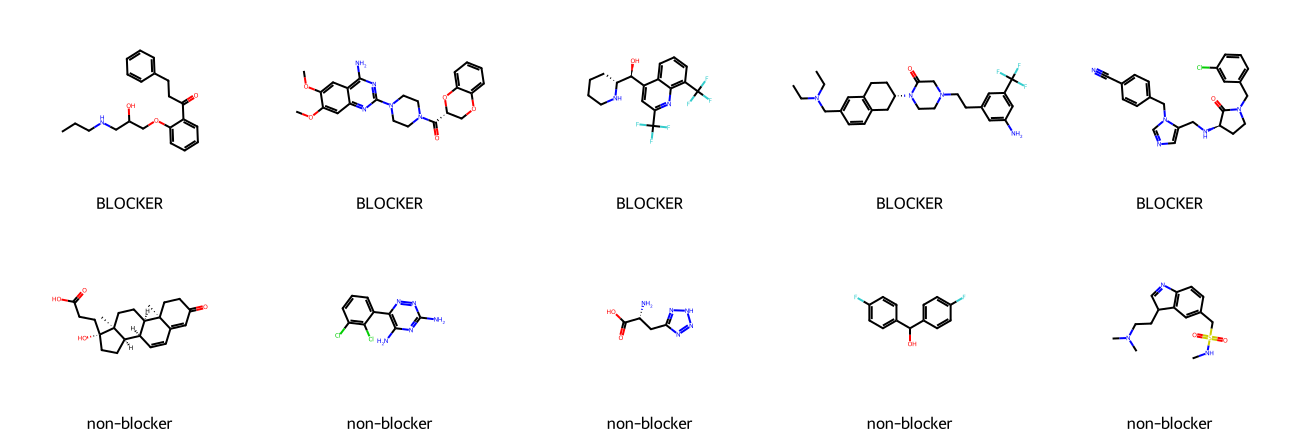

In [7]:
sample = pd.concat([data["hERG"].query("Y==1").sample(5, random_state=1),
                    data["hERG"].query("Y==0").sample(5, random_state=1)])
legends = [("BLOCKER" if y else "non-blocker") for y in sample.Y]
Draw.MolsToGridImage(list(sample.mol), molsPerRow=5, subImgSize=(260, 220), legends=legends)

## 2 &middot; Splitting without cheating &nbsp;&#9201;&#65039; ~5 min

This is the single most important methodological decision in the notebook. In drug discovery, chemists make *series* of close analogues. A **random split** puts siblings in both train and test, so the model "predicts" a test molecule by remembering its twin &mdash; and our score is inflated relative to the real job, which is predicting **genuinely new chemotypes**.

The standard fix is a **scaffold split**: group molecules by their Bemis&ndash;Murcko scaffold (the ring-system "core"), then put *whole groups* into train, validation or test. No scaffold ever straddles the boundary.

We split 80 / 10 / 10 (train / validation / test):
- **train** &mdash; fit models
- **validation** &mdash; choose hyper-parameters, the decision threshold and the probability calibrator
- **test** &mdash; never used for fitting, tuning or model selection; only *reported* on

In [8]:
def scaffold_split(scaffolds, y, fracs=(0.8, 0.1, 0.1), n_tries=300, seed=0):
    '''Randomised, class-balanced scaffold split.
    Whole scaffold groups are shuffled into train/valid/test (big groups go to train first). Among 300 random
    shuffles we keep the one whose valid/test positive rates are closest to the overall rate.'''
    groups = defaultdict(list)
    for i, s in enumerate(scaffolds):
        groups[s].append(i)
    sets = sorted(groups.values(), key=lambda g: (-len(g), g[0]))
    n = len(scaffolds); n_valid = fracs[1] * n; cut1, cut2 = fracs[0] * n, (fracs[0] + fracs[1]) * n
    big = [g for g in sets if len(g) > n_valid / 2]; small = [g for g in sets if len(g) <= n_valid / 2]
    base = sum(map(len, big)); rate = np.mean(y); rng = np.random.RandomState(seed); best = None
    for _ in range(n_tries):
        tr = [i for g in big for i in g]; va, te = [], []
        for k in rng.permutation(len(small)):
            g = small[k]
            if len(tr) + len(g) <= cut1: tr += g
            elif len(va) + len(g) <= cut2 - cut1: va += g
            else: te += g
        if len(va) < 0.07 * n or len(te) < 0.07 * n: continue
        cost = abs(np.mean(y[va]) - rate) + abs(np.mean(y[te]) - rate)
        if best is None or cost < best[0]: best = (cost, tr, va, te)
    _, tr, va, te = best
    return np.array(sorted(tr)), np.array(sorted(va)), np.array(sorted(te))

for ep, df in data.items():
    tr, va, te = scaffold_split(df.scaffold.tolist(), df.Y.to_numpy())
    df.store["split"] = (tr, va, te)
    # leakage check: no scaffold may appear in two partitions
    s_tr, s_va, s_te = (set(df.scaffold.iloc[i]) for i in (tr, va, te))
    # (acyclic molecules share the empty scaffold ''; that one group stays together in a single partition)
    assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), "scaffold leakage!"
    print(f"{ep:5s} train {len(tr):5d} | valid {len(va):4d} | test {len(te):4d} | "
          f"positive rate train/valid/test = {df.Y.iloc[tr].mean():.0%}/{df.Y.iloc[va].mean():.0%}/{df.Y.iloc[te].mean():.0%}")

hERG  train   485 | valid   60 | test   62 | positive rate train/valid/test = 68%/68%/69%


AMES  train  5804 | valid  725 | test  726 | positive rate train/valid/test = 54%/55%/55%


BBB   train  1564 | valid  195 | test  196 | positive rate train/valid/test = 76%/76%/77%


The assertion passing means **zero scaffold overlap** between partitions &mdash; the leakage guard is *enforced by code*, not by good intentions.

> **A lesson we learned the hard way.** Our first attempt used the textbook *deterministic* scaffold split (largest scaffold groups to train, rare singletons to valid/test). It produced absurd partitions: the hERG test set was only 5% positive and the BBB validation and test sets were **100% positive**, so ROC-AUC was not even defined. Because positives and negatives cluster in different chemical series, the order in which you hand out scaffolds can silently rewire the class balance. The fix above is a **randomised scaffold split that also searches for balanced class rates** (still with zero scaffold overlap). Always print the class balance of every partition.

> **Disclosure.** This search *uses the labels* to choose among 300 random shuffles. It shapes the class mix of the partitions (a form of stratification), not any model, but it does mean the test set is not a pure random draw of scaffolds. We could not use the textbook version, so we chose to say so plainly.

## 3 &middot; Turning molecules into numbers (and graphs) &nbsp;&#9201;&#65039; ~6 min

We compute three families of descriptors, all from RDKit:

| Block | Size | What it captures |
|---|---|---|
| **ECFP4 counts** (Morgan, radius 2) | 2,048 | which circular substructures are present, and how often |
| **MACCS keys** | 167 | 167 hand-curated medicinal-chemistry substructure questions |
| **RDKit 2D descriptors** | ~210 | physicochemical properties: logP, TPSA, MW, H-bond donors/acceptors, charge, ring counts &hellip; |

The concatenation ("**All**") is the input for the tree models. Missing values (a few descriptors fail on odd molecules) are left as `NaN`: tree models handle them natively, and the logistic-regression baseline only uses the ECFP block, which has no missing values, so no imputation (and no imputation leakage) is involved.

In [9]:
t0 = time.time()
for ep, df in data.items():
    mols = list(df.mol)
    cache = f"data/features_{ep}_{len(df)}.npy"          # cache: featurising takes ~4 min in total
    if os.path.exists(cache):
        df.store["X"] = np.load(cache)
    else:
        df.store["X"] = core.featurize(mols); np.save(cache, df.store["X"])
    df.store["fps"] = core.ecfp_bitvects(mols)
    df.store["y"] = df.Y.to_numpy()
    print(f"{ep:5s} feature matrix {df.store['X'].shape}, NaN cells: {np.isnan(df.store['X']).mean():.3%}")
print(f"Featurised in {time.time()-t0:.0f}s")

hERG  feature matrix (607, 2432), NaN cells: 0.001%


AMES  feature matrix (7255, 2432), NaN cells: 0.000%


BBB   feature matrix (1955, 2432), NaN cells: 0.000%
Featurised in 1s


In [10]:
def metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, yhat, zero_division=0), "MCC": matthews_corrcoef(y, yhat),
            "BalAcc": balanced_accuracy_score(y, yhat), "Brier": brier_score_loss(y, p)}

def best_threshold(y, p):
    '''Threshold maximising MCC on VALIDATION data (never on test).'''
    grid = np.linspace(0.1, 0.9, 81)
    return grid[int(np.argmax([matthews_corrcoef(y, (p >= t).astype(int)) for t in grid]))]

def lgbm(seed=0, **kw):
    params = dict(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.3, min_child_samples=10, reg_lambda=1.0, random_state=seed,
                  verbose=-1, n_jobs=8)
    params.update(kw)
    return lgb.LGBMClassifier(**params)

### 3.1 How much would a random split have flattered us?

Let's measure it rather than assert it: train the same LightGBM on the same features under a random split and under our scaffold split, with **5 repeats each** (different random seeds for both), and compare test ROC-AUC. One caveat: the scaffold arm is class-balanced by construction while the random arm is not.

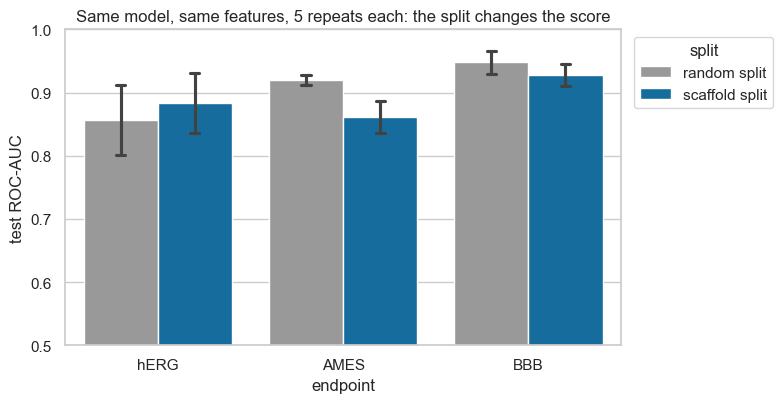

,random,scaffold,optimism (random - scaffold),sd across repeats (random/scaffold)
endpoint,,,,
AMES,0.920,0.861,0.059,0.008 / 0.025
BBB,0.948,0.928,0.020,0.019 / 0.018
hERG,0.857,0.883,-0.027,0.055 / 0.047


AMES : random split flatters the model by +0.059 ROC-AUC on average
BBB  : random split flatters the model by +0.020 ROC-AUC on average
hERG : random split does NOT flatter the model by -0.027 ROC-AUC on average


In [11]:
# ---- random vs scaffold split, same model, same features, 5 repeats each
leak_rows = []
for ep, df in data.items():
    X, y = df.store["X"], df.store["y"]; n = len(y)
    for r in range(5):
        perm = np.random.RandomState(r).permutation(n)
        rand = (perm[: int(.8 * n)], perm[int(.9 * n):])                     # random 80% train / 10% test
        tr, va, te = scaffold_split(df.scaffold.tolist(), y, seed=r)          # scaffold 80% train / 10% test
        for name, (a, b) in [("random split", rand), ("scaffold split", (tr, te))]:
            auc = roc_auc_score(y[b], lgbm(seed=r).fit(X[a], y[a]).predict_proba(X[b])[:, 1])
            leak_rows.append({"endpoint": ep, "split": name, "repeat": r, "test ROC-AUC": auc})
leak = pd.DataFrame(leak_rows)
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(data=leak, x="endpoint", y="test ROC-AUC", hue="split", errorbar="sd", capsize=0.1,
            palette=["#999999", "#0072B2"], ax=ax)
ax.set_ylim(0.5, 1.0); ax.set_title("Same model, same features, 5 repeats each: the split changes the score")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), title="split")
plt.tight_layout(); plt.show()

gap = (leak.pivot_table(index="endpoint", columns="split", values="test ROC-AUC", aggfunc=["mean", "std"]))
gap_tbl = pd.DataFrame({"random": gap[("mean", "random split")], "scaffold": gap[("mean", "scaffold split")]})
gap_tbl["optimism (random - scaffold)"] = gap_tbl["random"] - gap_tbl["scaffold"]
gap_tbl["sd across repeats (random/scaffold)"] = [f"{gap[('std','random split')][e]:.3f} / {gap[('std','scaffold split')][e]:.3f}" for e in gap_tbl.index]
display(gap_tbl.round(3))
for e, r in gap_tbl.iterrows():
    g = r["optimism (random - scaffold)"]
    print(f"{e:5s}: random split {'flatters' if g > 0 else 'does NOT flatter'} the model by {g:+.3f} ROC-AUC on average")

**How to read this.** The table above is the evidence. For **AMES** the random split flatters the model by about **+0.06 ROC-AUC** (0.92 against 0.86, far outside the repeat-to-repeat spread of 0.01 to 0.03), and for **BBB** by about **+0.02**. For **hERG** the two are indistinguishable: the difference is smaller than the ±0.05 spread across repeats, because that test fold holds only ~60 molecules. In industrial lead-optimisation data, where chemists make long series of near-identical analogues, the optimism is often reported to be larger still. We therefore use the scaffold split, which matches the real job (predicting new chemotypes) and cannot leak siblings. **From here on, every number in this notebook uses the scaffold split.**

### 3.2 Molecules as graphs

A molecule *is* a graph: atoms are nodes, bonds are edges. A **Graph Neural Network (GNN)** learns its own features by letting each atom repeatedly exchange "messages" with its neighbours, instead of relying on pre-defined fingerprints. We build the graph inputs below: atom features (element, degree, charge, hydrogens, hybridisation, aromaticity, ring membership) and bond features (type, conjugation, ring).

In [12]:
ATOM_Z = [6, 7, 8, 9, 15, 16, 17, 35, 53]
HYB = [Chem.HybridizationType.SP, Chem.HybridizationType.SP2, Chem.HybridizationType.SP3]
def onehot(v, choices):
    return [float(v == c) for c in choices] + [float(v not in choices)]

def atom_features(a):
    return (onehot(a.GetAtomicNum(), ATOM_Z) + onehot(a.GetDegree(), [1, 2, 3, 4]) +
            onehot(a.GetFormalCharge(), [-1, 0, 1]) + onehot(a.GetTotalNumHs(), [0, 1, 2, 3]) +
            onehot(a.GetHybridization(), HYB) + [float(a.GetIsAromatic()), float(a.IsInRing())])

BT = [Chem.BondType.SINGLE, Chem.BondType.DOUBLE, Chem.BondType.TRIPLE, Chem.BondType.AROMATIC]
def bond_features(b):
    return onehot(b.GetBondType(), BT)[:4] + [float(b.GetIsConjugated()), float(b.IsInRing())]

def mol_to_graph(m):
    x = torch.tensor([atom_features(a) for a in m.GetAtoms()], dtype=torch.float32)
    src, dst, ea = [], [], []
    for b in m.GetBonds():
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx(); f = bond_features(b)
        src += [i, j]; dst += [j, i]; ea += [f, f]
    ei = torch.tensor([src, dst], dtype=torch.long) if src else torch.zeros((2, 0), dtype=torch.long)
    ea = torch.tensor(ea, dtype=torch.float32) if ea else torch.zeros((0, 6))
    return x, ei, ea

for ep, df in data.items():
    df.store["graphs"] = [mol_to_graph(m) for m in df.mol]
N_ATOM_F = data["hERG"].store["graphs"][0][0].shape[1]
print(f"{N_ATOM_F} features per atom, 6 per bond. Example (first hERG molecule): "
      f"{data['hERG'].store['graphs'][0][0].shape[0]} atoms, {data['hERG'].store['graphs'][0][1].shape[1]//2} bonds")

30 features per atom, 6 per bond. Example (first hERG molecule): 33 atoms, 37 bonds


## 4 &middot; Baselines first, then advanced models &nbsp;&#9201;&#65039; ~25 min

A model score means nothing without something to compare it to. We build a **ladder of increasing sophistication**, so that every step up has to *earn* its place:

| Rung | Model | Idea |
|---|---|---|
| 0 | **Majority class** | knows nothing; ROC-AUC = 0.5 by construction |
| 1 | **kNN-Tanimoto** | "similar molecules behave alike": the QSPR idea from the earlier practical, as a classifier (k=5, similarity-weighted) |
| 2 | **Logistic regression** | linear model on ECFP counts (regularisation strength tuned by scaffold-grouped CV) |
| 3 | **Random Forest** | 500 trees on All features |
| 4 | **LightGBM** | gradient-boosted trees on All features, small grid tuned by scaffold-grouped CV |
| 5 | **GNN (GINE)** | learns its own representation from the molecular graph |
| 6 | **Ensemble** | average of the probabilities of 3&ndash;5 |

All stochastic models are run with **3 seeds** and we report mean &plusmn; standard deviation, so luck can't masquerade as skill.

### 4.1 Tuning on training data only (scaffold-grouped CV)

Hyper-parameters are chosen by 5-fold **GroupKFold on scaffolds *within the training set*** &mdash; the validation and test sets play no part.

In [13]:
def scaffold_groups(df, idx):
    codes = pd.factorize(df.scaffold.iloc[idx])[0]
    return codes

def cv_auc(make_model, X, y, groups, n_splits=5):
    aucs = []
    for a, b in GroupKFold(n_splits=n_splits).split(X, y, groups):
        m = make_model().fit(X[a], y[a])
        aucs.append(roc_auc_score(y[b], m.predict_proba(X[b])[:, 1]))
    return float(np.mean(aucs))

best_params = {}
t0 = time.time()
for ep, df in data.items():
    tr, va, te = df.store["split"]; X, y = df.store["X"], df.store["y"]; g = scaffold_groups(df, tr)
    # --- LightGBM: tiny grid over capacity and column sampling
    grid = [dict(num_leaves=nl, colsample_bytree=cs) for nl in (15, 31) for cs in (0.1, 0.3)]
    scores = [cv_auc(lambda p=p: lgbm(**p), X[tr], y[tr], g) for p in grid]
    best_params[(ep, "LightGBM")] = grid[int(np.argmax(scores))]
    # --- Logistic regression on ECFP counts: regularisation strength
    Xe = np.log1p(X[tr][:, :2048])
    Cs = (0.003, 0.01, 0.03, 0.1)
    lr_scores = [cv_auc(lambda C=C: LogisticRegression(C=C, max_iter=3000), Xe, y[tr], g) for C in Cs]
    best_params[(ep, "LR")] = {"C": Cs[int(np.argmax(lr_scores))]}
    print(f"{ep:5s} LightGBM best {best_params[(ep,'LightGBM')]} (CV AUC {max(scores):.3f}) | LR best C={best_params[(ep,'LR')]['C']} (CV AUC {max(lr_scores):.3f})")
print(f"tuning took {time.time()-t0:.0f}s")

hERG  LightGBM best {'num_leaves': 15, 'colsample_bytree': 0.1} (CV AUC 0.863) | LR best C=0.03 (CV AUC 0.852)


AMES  LightGBM best {'num_leaves': 31, 'colsample_bytree': 0.3} (CV AUC 0.839) | LR best C=0.1 (CV AUC 0.807)


BBB   LightGBM best {'num_leaves': 31, 'colsample_bytree': 0.1} (CV AUC 0.917) | LR best C=0.1 (CV AUC 0.909)
tuning took 275s


### 4.2 A Graph Neural Network from scratch

We write the GNN in plain PyTorch (no extra graph library needed, so it runs on a free CPU Colab). The layer is **GINE** (Graph Isomorphism Network with Edge features):

$$h_i' = \text{MLP}\Big((1+\varepsilon)\,h_i + \sum_{j \in \mathcal{N}(i)} \text{ReLU}\big(h_j + W_e\, e_{ij}\big)\Big)$$

In words: *each atom adds up what its neighbours are saying (modulated by the bond between them), mixes that with itself, and passes the result through a small neural net.* Stack three layers and each atom "sees" three bonds away. A **read-out** (mean and scaled sum over atoms) turns the atom vectors into one molecule vector, and a final linear layer outputs the probability. Training uses early stopping on **validation** ROC-AUC.

In [14]:
class GINELayer(nn.Module):
    def __init__(self, h, ed):
        super().__init__()
        self.edge = nn.Linear(ed, h)
        self.mlp = nn.Sequential(nn.Linear(h, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Linear(h, h))
        self.eps = nn.Parameter(torch.zeros(1))
    def forward(self, x, ei, ea):
        msg = F.relu(x[ei[0]] + self.edge(ea))                       # message from neighbour j along bond e_ij
        agg = torch.zeros_like(x).index_add_(0, ei[1], msg)           # sum messages arriving at each atom
        return self.mlp((1 + self.eps) * x + agg)

class MolGNN(nn.Module):
    def __init__(self, in_f, h=128, ed=6, layers=3, drop=0.2):
        super().__init__()
        self.inp = nn.Linear(in_f, h)
        self.layers = nn.ModuleList([GINELayer(h, ed) for _ in range(layers)])
        self.drop = nn.Dropout(drop)
        self.head = nn.Sequential(nn.Linear(2 * h, h), nn.ReLU(), nn.Dropout(drop), nn.Linear(h, 1))
    def forward(self, x, ei, ea, batch, n_graphs):
        h = self.inp(x)
        for L in self.layers:
            h = h + self.drop(F.relu(L(h, ei, ea)))                   # residual connection
        ones = torch.ones(h.shape[0], 1)
        cnt = torch.zeros(n_graphs, 1).index_add_(0, batch, ones)
        s = torch.zeros(n_graphs, h.shape[1]).index_add_(0, batch, h)
        return self.head(torch.cat([s / cnt, s / 30.0], dim=1)).squeeze(-1)   # mean + scaled-sum read-out

def collate(graphs):
    xs, eis, eas, bs, off = [], [], [], [], 0
    for i, (x, ei, ea) in enumerate(graphs):
        xs.append(x); eis.append(ei + off); eas.append(ea); bs.append(torch.full((x.shape[0],), i)); off += x.shape[0]
    return torch.cat(xs), torch.cat(eis, 1), torch.cat(eas), torch.cat(bs), len(graphs)

def gnn_predict(model, graphs, bs=256):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(graphs), bs):
            out.append(torch.sigmoid(model(*collate(graphs[i:i + bs]))))
    return torch.cat(out).numpy()

def train_gnn(graphs, y, tr, va, seed, epochs=60, patience=12, bs=64, lr=1e-3):
    set_seed(seed)
    model = MolGNN(N_ATOM_F); opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    g_tr, g_va = [graphs[i] for i in tr], [graphs[i] for i in va]
    best, best_state, bad = -1, {k: v.clone() for k, v in model.state_dict().items()}, 0
    rng = np.random.RandomState(seed)
    for epoch in range(epochs):
        model.train(); order = rng.permutation(len(tr))
        for i in range(0, len(order), bs):
            b = order[i:i + bs]
            if len(b) < 2: continue                                  # BatchNorm needs >1 sample
            logits = model(*collate([g_tr[j] for j in b]))
            loss = F.binary_cross_entropy_with_logits(logits, torch.tensor(y[tr][b], dtype=torch.float32))
            opt.zero_grad(); loss.backward(); opt.step()
        auc = roc_auc_score(y[va], gnn_predict(model, g_va))
        if auc > best: best, bad, best_state = auc, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    return model

### 4.3 Run the whole ladder

For each endpoint we fit every model, record validation and test probabilities for each seed, and keep them for the benchmark, calibration and error analysis later. (This is the longest cell: the GNN trains 3 seeds &times; 3 endpoints. Good moment for a coffee.)

In [15]:
from sklearn.neighbors import NearestNeighbors
preds = {ep: {} for ep in data}        # preds[ep][model][seed] = (p_valid, p_test)
fitted = {ep: {} for ep in data}       # keep one fitted model per type for later sections
timings = defaultdict(float)

def knn_tanimoto(fps, y, tr, query_idx, k=5):
    train_fps = [fps[i] for i in tr]; out = []
    for q in query_idx:
        sims = np.array(core.DataStructs.BulkTanimotoSimilarity(fps[q], train_fps))
        top = np.argsort(-sims)[:k]; w = sims[top] + 1e-6
        out.append(float((w * y[tr][top]).sum() / w.sum()))
    return np.array(out)

for ep, df in data.items():
    tr, va, te = df.store["split"]; X, y, fps, graphs = df.store["X"], df.store["y"], df.store["fps"], df.store["graphs"]
    P = preds[ep]
    def rec(name, seed, pv, pt): P.setdefault(name, {})[seed] = (np.asarray(pv), np.asarray(pt))

    t = time.time()
    d = DummyClassifier(strategy="prior").fit(X[tr], y[tr])
    rec("Majority class", 0, d.predict_proba(X[va])[:, 1], d.predict_proba(X[te])[:, 1])
    rec("kNN-Tanimoto", 0, knn_tanimoto(fps, y, tr, va), knn_tanimoto(fps, y, tr, te)); timings["kNN"] += time.time() - t

    t = time.time()
    lr = LogisticRegression(C=best_params[(ep, "LR")]["C"], max_iter=3000).fit(np.log1p(X[tr][:, :2048]), y[tr])
    rec("Logistic regression", 0, lr.predict_proba(np.log1p(X[va][:, :2048]))[:, 1], lr.predict_proba(np.log1p(X[te][:, :2048]))[:, 1])
    timings["LR"] += time.time() - t

    for s in SEEDS:
        t = time.time()
        rf = RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=s)
        rf.fit(X[tr], y[tr])                              # scikit-learn >= 1.4 forests handle NaN natively
        rec("Random Forest", s, rf.predict_proba(X[va])[:, 1], rf.predict_proba(X[te])[:, 1])
        timings["RF"] += time.time() - t
        t = time.time()
        gb = lgbm(seed=s, **best_params[(ep, "LightGBM")]).fit(X[tr], y[tr])
        rec("LightGBM", s, gb.predict_proba(X[va])[:, 1], gb.predict_proba(X[te])[:, 1])
        timings["LGBM"] += time.time() - t
        t = time.time()
        gnn = train_gnn(graphs, y, tr, va, s)
        rec("GNN (GINE)", s, gnn_predict(gnn, [graphs[i] for i in va]), gnn_predict(gnn, [graphs[i] for i in te]))
        timings["GNN"] += time.time() - t
        if s == SEEDS[0]:
            fitted[ep].update({"LightGBM": gb, "RF": rf, "GNN": gnn, "LR": lr})
    # ensemble: per-seed average of RF + LightGBM + GNN
    for s in SEEDS:
        rec("Ensemble", s, np.mean([P[m][s][0] for m in ("Random Forest", "LightGBM", "GNN (GINE)")], axis=0),
                           np.mean([P[m][s][1] for m in ("Random Forest", "LightGBM", "GNN (GINE)")], axis=0))
    print(f"{ep:5s} done")
print({k: f"{v:.0f}s" for k, v in timings.items()})

hERG  done


AMES  done


BBB   done
{'kNN': '10s', 'LR': '2s', 'RF': '54s', 'LGBM': '50s', 'GNN': '787s'}


## 5 &middot; The benchmarking report &nbsp;&#9201;&#65039; ~5 min

Now the moment of truth, on the **held-out scaffold test set**. For each model the decision threshold is picked on the *validation* set (maximising MCC) and then applied unchanged to the test set. ROC-AUC and PR-AUC don't need a threshold; F1, MCC and balanced accuracy do.

In [16]:
MODELS = ["Majority class", "kNN-Tanimoto", "Logistic regression", "Random Forest", "LightGBM", "GNN (GINE)", "Ensemble"]
rows = []
for ep, df in data.items():
    tr, va, te = df.store["split"]; y = df.store["y"]
    for m in MODELS:
        for s, (pv, pt) in preds[ep][m].items():
            thr = best_threshold(y[va], pv) if m != "Majority class" else 0.5
            rows.append({"endpoint": ep, "model": m, "seed": s, "thr": thr, **metrics(y[te], pt, thr)})
bench = pd.DataFrame(rows)
summ = bench.groupby(["endpoint", "model"]).agg(**{c: (c, "mean") for c in ["ROC-AUC", "PR-AUC", "F1", "MCC", "BalAcc", "Brier"]},
                                                   AUC_sd=("ROC-AUC", "std")).reset_index()
auc_table = summ.pivot(index="model", columns="endpoint", values="ROC-AUC").loc[MODELS]
sd_table = summ.pivot(index="model", columns="endpoint", values="AUC_sd").loc[MODELS].fillna(0)
pretty = auc_table.round(3).astype(str) + " ± " + sd_table.round(3).astype(str)
pretty["mean AUC"] = auc_table.mean(axis=1).round(3)
print("Test ROC-AUC (mean ± sd over 3 seeds; deterministic models have sd = 0):")
display(pretty)

Test ROC-AUC (mean ± sd over 3 seeds; deterministic models have sd = 0):


endpoint,AMES,BBB,hERG,mean AUC
model,,,,
Majority class,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.500
kNN-Tanimoto,0.845 ± 0.0,0.836 ± 0.0,0.829 ± 0.0,0.837
Logistic regression,0.855 ± 0.0,0.874 ± 0.0,0.905 ± 0.0,0.878
Random Forest,0.885 ± 0.001,0.917 ± 0.002,0.908 ± 0.01,0.904
LightGBM,0.889 ± 0.003,0.917 ± 0.005,0.845 ± 0.006,0.884
GNN (GINE),0.849 ± 0.009,0.91 ± 0.002,0.815 ± 0.01,0.858
Ensemble,0.891 ± 0.005,0.913 ± 0.007,0.9 ± 0.006,0.901


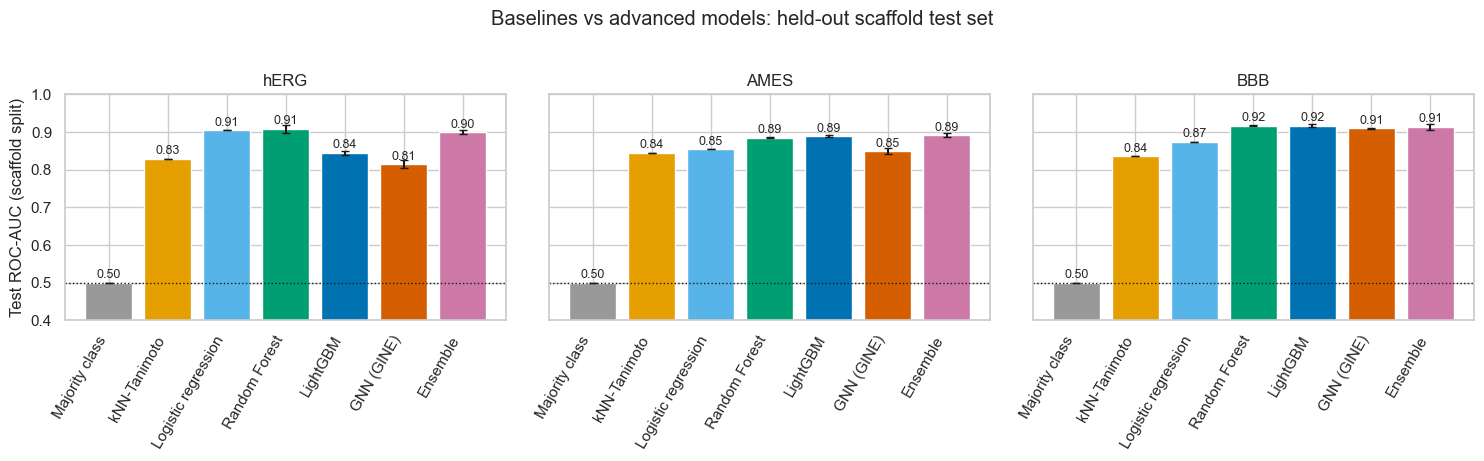

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, ep in zip(axes, data):
    sub = summ[summ.endpoint == ep].set_index("model").loc[MODELS]
    ax.bar(range(len(MODELS)), sub["ROC-AUC"], yerr=sub["AUC_sd"].fillna(0), color=[PALETTE[m] for m in MODELS],
           capsize=3, edgecolor="white")
    ax.axhline(0.5, color="k", ls=":", lw=1)
    ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(MODELS, rotation=60, ha="right")
    ax.set_title(f"{ep}"); ax.set_ylim(0.4, 1.0)
    for i, v in enumerate(sub["ROC-AUC"]): ax.text(i, v + 0.012, f"{v:.2f}", ha="center", fontsize=9)
axes[0].set_ylabel("Test ROC-AUC (scaffold split)")
plt.suptitle("Baselines vs advanced models: held-out scaffold test set", y=1.02); plt.tight_layout(); plt.show()

In [18]:
print("Full metric table at the validation-chosen threshold (mean over seeds):")
full = summ.set_index(["endpoint", "model"])[["ROC-AUC", "PR-AUC", "F1", "MCC", "BalAcc", "Brier"]].round(3)
display(full)

Full metric table at the validation-chosen threshold (mean over seeds):


ROC-AUC  PR-AUC     F1    MCC  BalAcc  Brier
endpoint model                                                            
AMES     Ensemble               0.891   0.919  0.821  0.618   0.810  0.134
         GNN (GINE)             0.849   0.876  0.786  0.537   0.767  0.159
         LightGBM               0.889   0.918  0.814  0.628   0.814  0.134
         Logistic regression    0.855   0.876  0.803  0.563   0.781  0.155
         Majority class         0.500   0.547  0.707  0.000   0.500  0.248
         Random Forest          0.885   0.913  0.825  0.616   0.808  0.140
         kNN-Tanimoto           0.845   0.838  0.804  0.557   0.777  0.164
BBB      Ensemble               0.913   0.970  0.922  0.632   0.792  0.090
         GNN (GINE)             0.910   0.970  0.926  0.640   0.777  0.101
         LightGBM               0.917   0.970  0.917  0.601   0.771  0.107
         Logistic regression    0.874   0.956  0.914  0.555   0.712  0.114
         Majority class         0.500   0.770  0.870  0.000   0.500  0.177
         Random Forest          0.917   0.970  0.922  0.606   0.737  0.090
         kNN-Tanimoto           0.836   0.917  0.901  0.561   0.776  0.106
hERG     Ensemble               0.900   0.944  0.874  0.532   0.732  0.131
         GNN (GINE)             0.815   0.852  0.855  0.438   0.680  0.163
         LightGBM               0.845   0.903  0.872  0.536   0.742  0.140
         Logistic regression    0.905   0.937  0.866  0.475   0.673  0.145
         Majority class         0.500   0.694  0.819  0.000   0.500  0.213
         Random Forest          0.908   0.955  0.896  0.633   0.794  0.125
         kNN-Tanimoto           0.829   0.887  0.851  0.424   0.676  0.146

### 5.1 Is the difference real? Uncertainty on a small test set

The hERG test set holds only a few dozen molecules, so a 0.02 gap between two models could easily be noise. We bootstrap the test set (1,000 resamples) to put a **95% confidence interval** on each endpoint's best-model ROC-AUC, and a *paired* bootstrap for "Ensemble minus best baseline".

In [19]:
rng = np.random.RandomState(0)
ci_rows = []
for ep, df in data.items():
    tr, va, te = df.store["split"]; y = df.store["y"][te]
    pt = {m: np.mean([preds[ep][m][s][1] for s in preds[ep][m]], axis=0) for m in MODELS}
    va_auc = lambda m: np.mean([roc_auc_score(data[ep].store["y"][va], preds[ep][m][s][0]) for s in preds[ep][m]])
    # models are chosen on VALIDATION AUC, never on the test set we are about to report
    baseline = max(["kNN-Tanimoto", "Logistic regression"], key=va_auc)
    best_adv = max(["Random Forest", "LightGBM", "GNN (GINE)", "Ensemble"], key=va_auc)
    boot_adv, boot_diff = [], []
    for _ in range(1000):
        i = rng.randint(0, len(y), len(y))
        if len(set(y[i])) < 2: continue
        a, b = roc_auc_score(y[i], pt[best_adv][i]), roc_auc_score(y[i], pt[baseline][i])
        boot_adv.append(a); boot_diff.append(a - b)
    ci_rows.append({"endpoint": ep, "n_test": len(y), "best advanced": best_adv, "AUC": roc_auc_score(y, pt[best_adv]),
                    "95% CI": f"[{np.percentile(boot_adv, 2.5):.3f}, {np.percentile(boot_adv, 97.5):.3f}]",
                    "best baseline": baseline, "gain vs baseline": np.mean(boot_diff),
                    "gain 95% CI": f"[{np.percentile(boot_diff, 2.5):.3f}, {np.percentile(boot_diff, 97.5):.3f}]"})
ci_table = pd.DataFrame(ci_rows).set_index("endpoint"); display(ci_table.round(3))

,n_test,best advanced,AUC,95% CI,best baseline,gain vs baseline,gain 95% CI
endpoint,,,,,,,
hERG,62,Ensemble,0.898,"[0.795, 0.977]",Logistic regression,-0.007,"[-0.066, 0.043]"
AMES,726,Ensemble,0.893,"[0.869, 0.915]",kNN-Tanimoto,0.048,"[0.027, 0.070]"
BBB,196,Random Forest,0.917,"[0.865, 0.960]",kNN-Tanimoto,0.082,"[0.030, 0.144]"


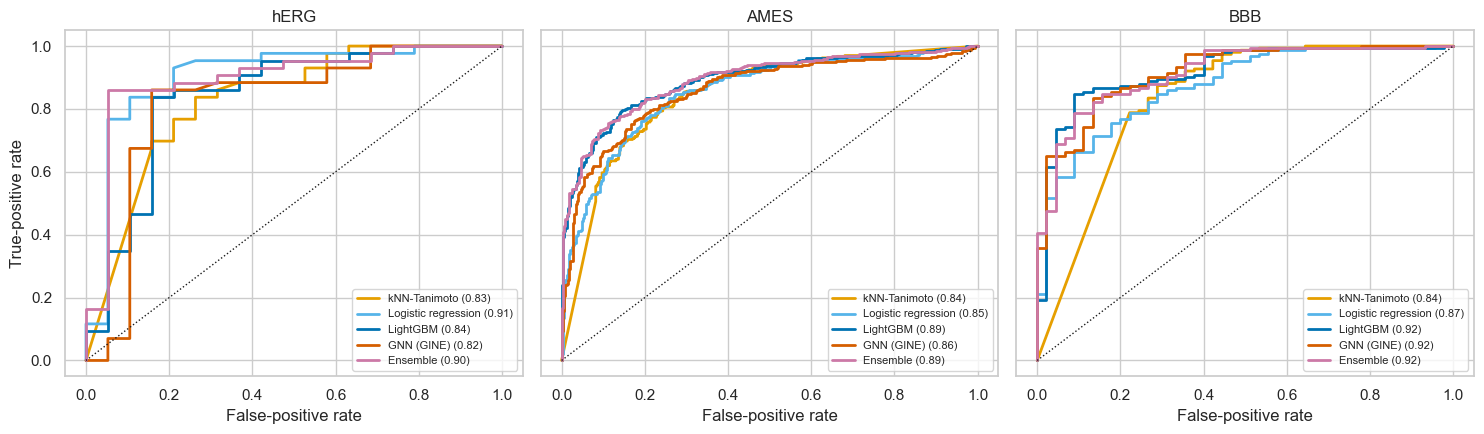

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, ep in zip(axes, data):
    tr, va, te = data[ep].store["split"]; y = data[ep].store["y"][te]
    for m in ["kNN-Tanimoto", "Logistic regression", "LightGBM", "GNN (GINE)", "Ensemble"]:
        p = np.mean([preds[ep][m][s][1] for s in preds[ep][m]], axis=0)
        fpr, tpr, _ = roc_curve(y, p); ax.plot(fpr, tpr, color=PALETTE[m], lw=2, label=f"{m} ({roc_auc_score(y, p):.2f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_title(ep); ax.set_xlabel("False-positive rate"); ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("True-positive rate"); plt.tight_layout(); plt.show()

### 5.2 The model we actually ship, against each baseline

The table in 5.1 picked its "best advanced" model on validation AUC, which can be the ensemble. The model we **ship** is the validation-selected tree ensemble from section 6.1, so here is its own paired-bootstrap comparison against *both* baselines (logistic regression and nearest-neighbour), on the same 1,000 resamples of the test set.

In [21]:
rng = np.random.RandomState(1)
head_rows = []
for ep, df in data.items():
    tr, va, te = df.store["split"]; y = df.store["y"][te]
    pt = {m: np.mean([preds[ep][m][s][1] for s in preds[ep][m]], axis=0) for m in MODELS}
    dep_name = max(["Random Forest", "LightGBM"], key=lambda m: np.mean([roc_auc_score(df.store["y"][va], preds[ep][m][s][0]) for s in SEEDS]))
    boots = []
    for _ in range(1000):
        i = rng.randint(0, len(y), len(y))
        if len(set(y[i])) == 2: boots.append(i)
    def ci(fn): v = [fn(i) for i in boots]; return f"[{np.percentile(v, 2.5):+.3f}, {np.percentile(v, 97.5):+.3f}]", np.mean(v)
    row = {"endpoint": ep, "deployed model": dep_name, "test AUC": roc_auc_score(y, pt[dep_name])}
    for b in ("Logistic regression", "kNN-Tanimoto"):
        c, m_ = ci(lambda i: roc_auc_score(y[i], pt[dep_name][i]) - roc_auc_score(y[i], pt[b][i]))
        row[f"gain vs {b}"] = roc_auc_score(y, pt[dep_name]) - roc_auc_score(y, pt[b]); row[f"95% CI vs {b}"] = c
    head_rows.append(row)
headline = pd.DataFrame(head_rows).set_index("endpoint"); display(headline.round(3))

,deployed model,test AUC,gain vs Logistic regression,95% CI vs Logistic regression,gain vs kNN-Tanimoto,95% CI vs kNN-Tanimoto
endpoint,,,,,,
hERG,Random Forest,0.909,0.004,"[-0.054, +0.057]",0.081,"[-0.049, +0.223]"
AMES,Random Forest,0.886,0.031,"[+0.013, +0.050]",0.041,"[+0.019, +0.064]"
BBB,Random Forest,0.917,0.043,"[-0.006, +0.090]",0.081,"[+0.029, +0.142]"


**How to read this.** The deployed Random Forest is clearly better than the nearest-neighbour baseline on AMES and BBB (the intervals exclude zero). Against the stronger logistic-regression baseline the picture is more modest: a real but small gain on **AMES** (+0.031, CI +0.013 to +0.050), a gain on **BBB** whose interval just touches zero (+0.043, CI −0.006 to +0.090), and **no detectable gain on hERG** (+0.004, CI −0.054 to +0.057). On the test set logistic regression is the strongest baseline for all three endpoints, so this is the conservative comparison to quote.

### 5.3 What the benchmark tells us

**1. Every real model beats the trivial baseline by a mile** (the majority class sits at ROC-AUC 0.5), so there is genuine signal to learn.

**2. Advanced models help where data is plentiful and barely at all where it is scarce.**
- **AMES** (5,804 training molecules): the tree ensembles reach ≈0.89 against 0.855 for logistic regression and 0.845 for nearest-neighbour. The deployed forest beats the strongest baseline by **+0.031 ROC-AUC (95% CI +0.013 to +0.050)**: a real but modest gain.
- **BBB** (1,564): the forest reaches 0.917 against 0.874 for logistic regression and 0.836 for nearest-neighbour. It is clearly ahead of nearest-neighbour (+0.081), but only +0.043 ahead of logistic regression, with a 95% interval (−0.006 to +0.090) that includes zero.
- **hERG** (485): Random Forest 0.909 against 0.905 for plain logistic regression on ECFP counts (gain +0.004, CI −0.054 to +0.057). With only ~60 test molecules the test AUC itself carries a ±0.09 interval. The honest reading is that on hERG we cannot claim that complexity pays.

**3. The Graph Neural Network did not win.** It scores 0.82 (hERG), 0.85 (AMES) and 0.91 (BBB), below the tree ensembles everywhere. That is not a bug (it trains and early-stops normally). A plausible reason is that a GNN trained from scratch on a few hundred to a few thousand molecules has little to learn from, but we did **not** test this (no learning curves) and we did not tune the GNN's architecture, so it may simply be under-tuned. GNNs often pay off with much more data or pre-training. We keep it in the ensemble because diversity helps robustness, but with fingerprints plus descriptors the trees are the better value here.

**4. LightGBM's weak hERG score (0.845, versus 0.908 for Random Forest on the same features) is a small-data warning.** We have not proven why, but with 485 training molecules boosting is plausibly more prone to overfit than a forest. It is exactly why the deployed model is chosen on *validation* data in section 6.1, not assumed.

**Question:** on hERG, LightGBM (0.845) trails Random Forest (0.908) although both see exactly the same features. What might explain it, and what would you try?

<details>
<summary><b>Answer</b></summary>

With only 485 training molecules a boosted model, which fits sequentially and can chase noise, is easier to overfit than a forest, which averages many independent trees. We have not proven this. Things to try: stronger regularisation (fewer leaves, larger `min_child_samples`, lower learning rate), early stopping on the validation set, or simply keeping the forest. Note also that the validation AUCs (0.871 vs 0.887) are much closer than the test AUCs, a reminder of how noisy a 62-molecule test set is.

</details>

**5. The seed-to-seed spread is small** (standard deviations ≤ 0.02), so these conclusions are not seed luck. The bigger uncertainty is the *test-set size*, which the bootstrap intervals above capture.

## 6 &middot; Which model do we ship, and what did it learn? &nbsp;&#9201;&#65039; ~5 min

### 6.1 Choosing the deployed model (on validation data only)

For the product we want something fast, small, GPU-free and explainable, so the candidates are the two tree ensembles. For each endpoint we pick the one with the higher **validation** ROC-AUC (averaged over seeds). Picking on the test set would quietly leak test information into the model choice, so we don't.

In [22]:
DEPLOY, sel_rows = {}, []
FITTED_KEY = {"Random Forest": "RF", "LightGBM": "LightGBM"}
for ep, df in data.items():
    tr, va, te = df.store["split"]; y = df.store["y"]
    cand = {m: np.mean([roc_auc_score(y[va], preds[ep][m][s][0]) for s in SEEDS]) for m in FITTED_KEY}
    DEPLOY[ep] = max(cand, key=cand.get)
    sel_rows.append({"endpoint": ep, **{f"validation AUC: {m}": v for m, v in cand.items()}, "deployed": DEPLOY[ep]})
display(pd.DataFrame(sel_rows).set_index("endpoint").round(3))

,validation AUC: Random Forest,validation AUC: LightGBM,deployed
endpoint,,,
hERG,0.887,0.871,Random Forest
AMES,0.874,0.868,Random Forest
BBB,0.930,0.914,Random Forest


### 6.2 What did the model learn? (SHAP)

A prediction a chemist cannot interrogate is a prediction a chemist will not trust. **SHAP** values attribute each prediction to the input features, as in the earlier SHAP lecture. We explain the *deployed* model for each endpoint (on up to 150 test molecules, to keep it quick) and show the 12 most influential features. A sensible model should rediscover known medicinal chemistry; if it instead leans on junk, we want to know.

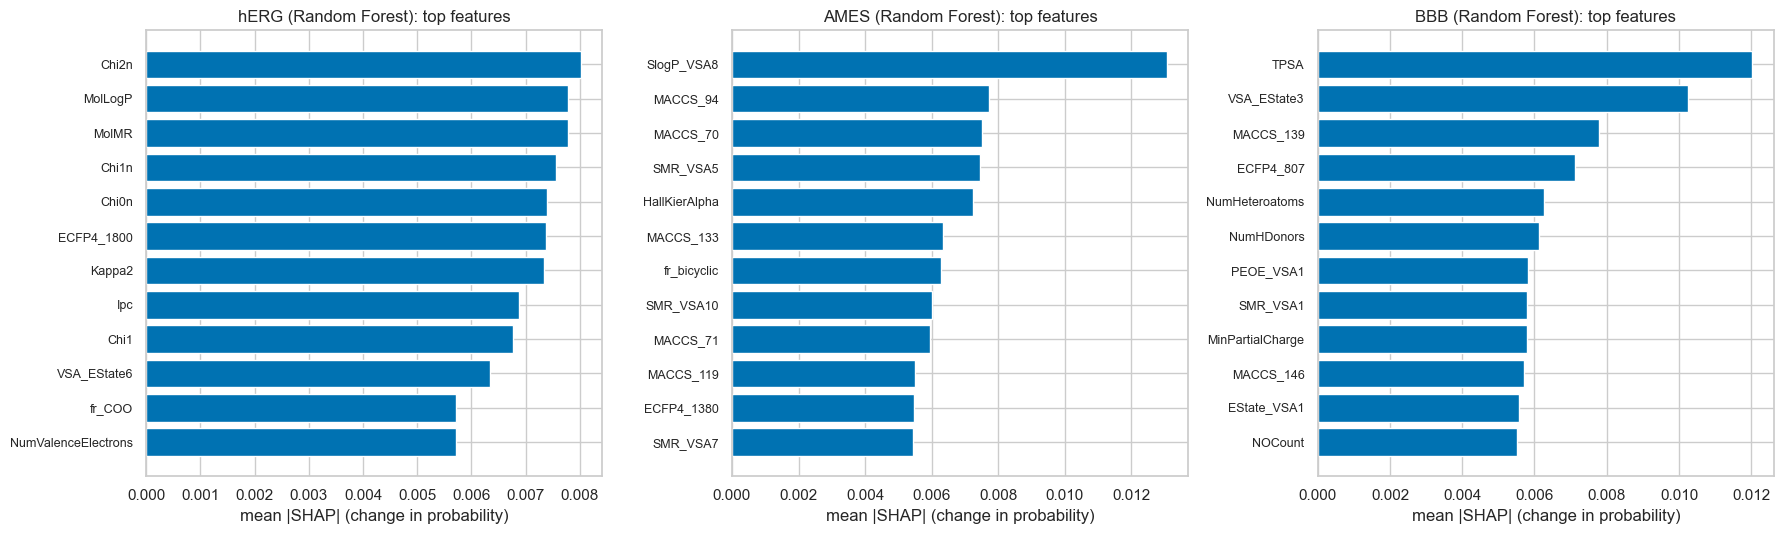

In [23]:
import shap
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
shap_store = {}
for ax, ep in zip(axes, data):
    df = data[ep]; tr, va, te = df.store["split"]; X = df.store["X"]
    idx = te[np.random.RandomState(0).permutation(len(te))[:150]]
    model = fitted[ep][FITTED_KEY[DEPLOY[ep]]]
    sv = shap.TreeExplainer(model).shap_values(X[idx])
    sv = sv[1] if isinstance(sv, list) else sv
    if sv.ndim == 3: sv = sv[:, :, 1]                      # (samples, features, classes) -> positive class
    shap_store[ep] = (idx, sv)
    imp = np.abs(sv).mean(0); top = np.argsort(imp)[::-1][:12]
    ax.barh(range(12)[::-1], imp[top], color="#0072B2")
    ax.set_yticks(range(12)[::-1]); ax.set_yticklabels([core.FEATURE_NAMES[i] for i in top], fontsize=9)
    ax.set_title(f"{ep} ({DEPLOY[ep]}): top features"); ax.set_xlabel("mean |SHAP| (change in probability)")
plt.tight_layout(); plt.show()

**Does the model rediscover known chemistry?** Largely yes (the values are in probability units, because Random Forest SHAP explains the predicted probability).

- **BBB** is the cleanest story. The top features are **TPSA (polar surface area), number of heteroatoms, H-bond donors** and polar surface-area descriptors, and in the beeswarm *high* values push the prediction firmly towards "does not cross". That is the classic CNS rule of thumb (roughly TPSA below ~90 Å² and few H-bond donors), learned from data without being told.
- **hERG** leans on **lipophilicity (MolLogP), molecular size and shape (MolMR, Chi and Kappa connectivity indices)** and a count of **carboxylic acids (`fr_COO`)**. Large, greasy molecules push towards "blocker" while small polar ones are pulled strongly towards "non-blocker". Adding an acid is a standard tactic to design hERG activity out, so the `fr_COO` feature is plausible, although its direction is not shown in the beeswarm below. Notably, the textbook hERG pharmacophore (a basic nitrogen) is *not* among the top features, so the model is leaning mostly on size and lipophilicity proxies. One ECFP bit (`ECFP4_1800`) also matters; decoding which atoms it encodes would be a good extension.
- **AMES** is the least interpretable: the top features are surface-area-weighted lipophilicity/refractivity descriptors and several MACCS keys. The model predicts mutagenicity partly through broad aromatic-system "size and shape" proxies, not through the specific structural alerts toxicologists use (aromatic nitro groups, aromatic amines, epoxides and so on). That is a real limitation; adding explicit structural alerts as features is a sensible next step.

Takeaway: for two of three endpoints the model's reasoning is chemically sensible, and for the third we know what its reasoning is *not*. That is what makes it reasonable to present as a triage aid.

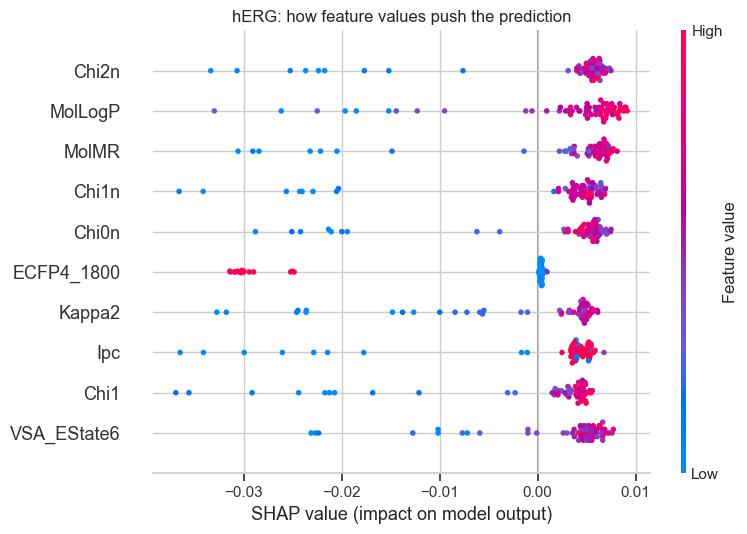

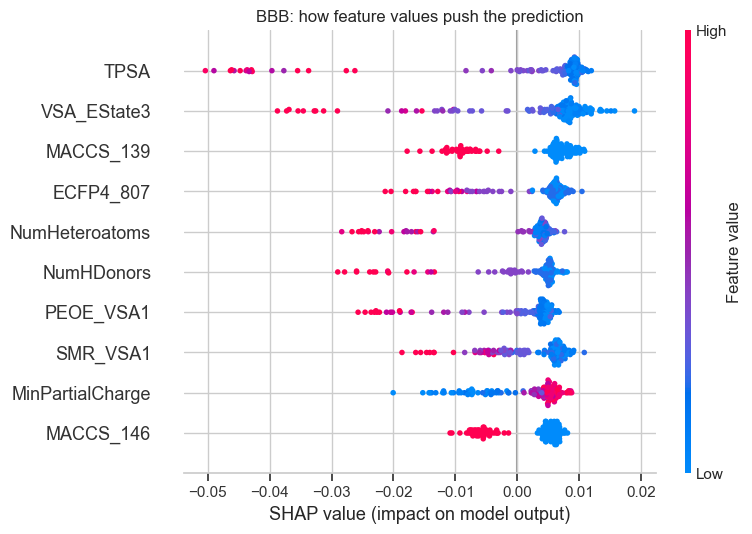

In [24]:
# Direction of effect for the most important descriptors (beeswarm), hERG and BBB
for ep in ["hERG", "BBB"]:
    df = data[ep]; tr, va, te = df.store["split"]
    idx, sv = shap_store[ep]
    shap.summary_plot(sv, df.store["X"][idx], feature_names=core.FEATURE_NAMES, max_display=10, show=False)
    plt.title(f"{ep}: how feature values push the prediction"); plt.tight_layout(); plt.show()

## 7 &middot; Guardrail 1: can we trust the probabilities? &nbsp;&#9201;&#65039; ~4 min

A model that says "92% hERG-risk" should be right about 92% of the time such statements are made. That property is **calibration**, and tree ensembles usually don't have it out of the box. We fix it with **Platt scaling** (a one-parameter-pair sigmoid on the model's logit), fitted on the **validation set only**, then check the reliability curve on the **test set**.

We calibrate the **deployed model** chosen in section 6.1 (fast, small, no GPU, explainable with SHAP).

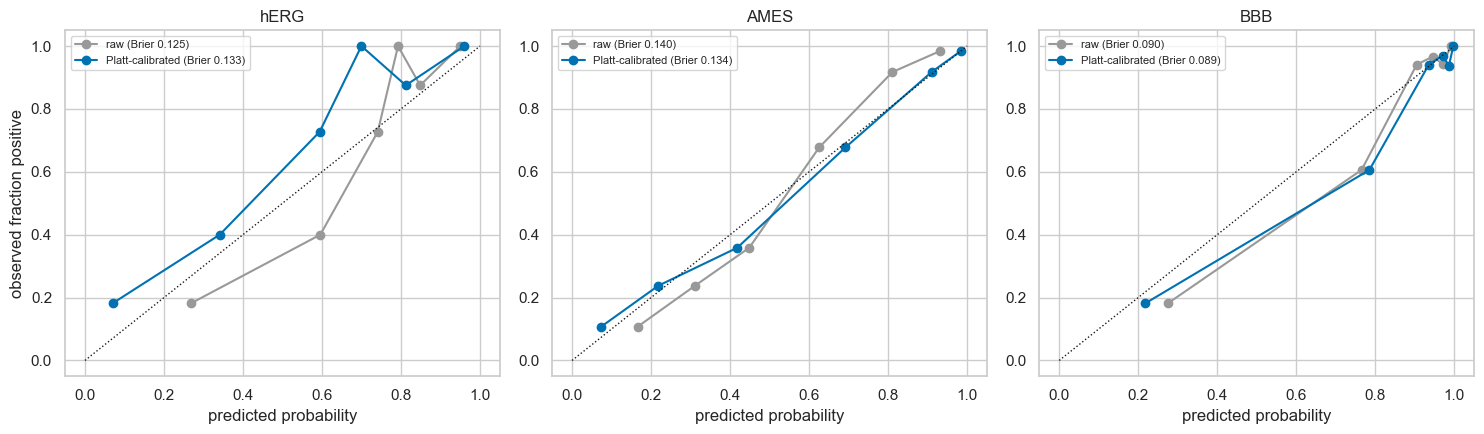

,Brier raw,Brier calibrated
endpoint,,
hERG,0.1254,0.1330
AMES,0.1396,0.1344
BBB,0.0899,0.0894


In [25]:
calibrators = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
cal_rows = []
for ax, ep in zip(axes, data):
    df = data[ep]; tr, va, te = df.store["split"]; y = df.store["y"]
    pv, pt = preds[ep][DEPLOY[ep]][0]
    cal = core.PlattCalibrator().fit(pv, y[va]); calibrators[ep] = cal
    pt_cal = cal.predict(pt)
    for name, p, c in [("raw", pt, "#999999"), ("Platt-calibrated", pt_cal, "#0072B2")]:
        frac, mean_p = calibration_curve(y[te], p, n_bins=6, strategy="quantile")
        ax.plot(mean_p, frac, "o-", color=c, label=f"{name} (Brier {brier_score_loss(y[te], p):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_title(ep); ax.set_xlabel("predicted probability"); ax.legend(fontsize=8)
    cal_rows.append({"endpoint": ep, "Brier raw": brier_score_loss(y[te], pt), "Brier calibrated": brier_score_loss(y[te], pt_cal)})
axes[0].set_ylabel("observed fraction positive"); plt.tight_layout(); plt.show()
display(pd.DataFrame(cal_rows).set_index("endpoint").round(4))

**A mixed result, reported honestly.** Platt scaling improved the Brier score for AMES (0.140 → 0.134) and was neutral for BBB (0.090 → 0.089), but made **hERG slightly worse** (0.125 → 0.133). The reason is visible in the leftmost panel: only 60 molecules fit the hERG calibrator, so the sigmoid it learns is noisy, and the six-bin reliability curve on 62 test molecules is itself jagged. Two lessons:

1. Calibration needs a few hundred validation molecules; with fewer, treat probabilities as **rankings with rough meaning**, not exact risk percentages.
2. In production, pool cross-validated out-of-fold predictions to fit the calibrator on much more data.

We keep calibration in the pipeline for consistency and flag the hERG probabilities as approximate.

**Question:** calibration helped AMES but hurt hERG. Which dataset property explains the difference, and how would you fix it?

<details>
<summary><b>Answer</b></summary>

The number of molecules available to fit the calibrator: ~725 for AMES but only 60 for hERG. A sigmoid with two parameters fitted to 60 points is noisy. The fix is to pool out-of-fold predictions from cross-validation on the whole training set and fit the calibrator on those.

</details>

## 8 &middot; Guardrail 2: knowing what we don't know &nbsp;&#9201;&#65039; ~5 min

In clinical settings the dangerous failure is **confident nonsense**. We add two defences, both enforced by `core.verdict()`:

1. **Applicability domain (AD).** If a query molecule's nearest neighbour in the training set has Tanimoto similarity below **0.30**, it's structurally alien to anything the model has seen, and the app answers **OUT OF DOMAIN** instead of a number.
2. **Uncertainty band.** If the calibrated probability lies in **0.40&ndash;0.60**, the model effectively shrugs, and the app answers **UNCERTAIN**.

Do these actually help? A guardrail is only justified if accuracy *really is* worse outside the safe zone. Let's test that on the held-out test set: accuracy by similarity bin.

endpoint,AMES,BBB,hERG
max similarity to train,,,
0.30-0.45,0.71,0.88,0.78
0.45-0.60,0.83,0.91,1.00
<0.30 (out),0.83,0.82,0.71
>=0.60,0.89,0.92,0.96


endpoint,AMES,BBB,hERG
max similarity to train,,,
0.30-0.45,220,68,9
0.45-0.60,226,55,1
<0.30 (out),88,34,24
>=0.60,192,39,28


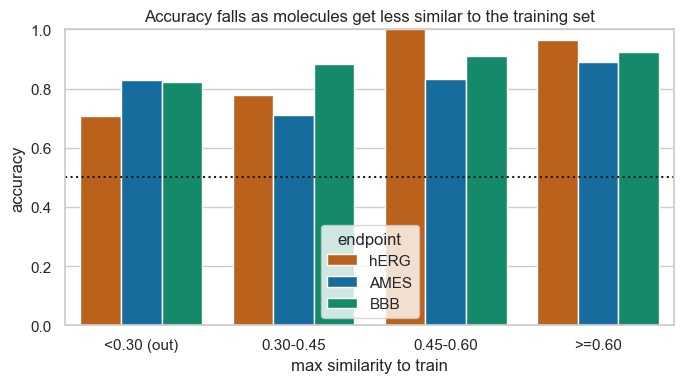

In [26]:
ad_rows = []; ad_cache = {}
for ep, df in data.items():
    tr, va, te = df.store["split"]; y = df.store["y"]
    train_fps = [df.store["fps"][i] for i in tr]
    sim = core.max_similarity([df.store["fps"][i] for i in te], train_fps)
    p = calibrators[ep].predict(preds[ep][DEPLOY[ep]][0][1])
    ad_cache[ep] = (sim, p)
    bins = pd.cut(sim, [0, 0.3, 0.45, 0.6, 1.01], labels=["<0.30 (out)", "0.30-0.45", "0.45-0.60", ">=0.60"], right=False, include_lowest=True)
    for b in bins.categories:
        mask = np.asarray(bins == b)
        if mask.sum() >= 1:
            acc = ((p[mask] >= 0.5) == y[te][mask]).mean()
            ad_rows.append({"endpoint": ep, "max similarity to train": b, "n": int(mask.sum()), "accuracy": acc})
ad = pd.DataFrame(ad_rows)
display(ad.pivot(index="max similarity to train", columns="endpoint", values="accuracy").round(2))
display(ad.pivot(index="max similarity to train", columns="endpoint", values="n"))
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=ad, x="max similarity to train", y="accuracy", hue="endpoint", palette=["#D55E00", "#0072B2", "#009E73"], ax=ax)
ax.set_ylim(0, 1); ax.axhline(0.5, color="k", ls=":"); ax.set_title("Accuracy falls as molecules get less similar to the training set")
plt.tight_layout(); plt.show()

**What the table says, and what it doesn't.** For **hERG** accuracy climbs with similarity: 0.96 for molecules at similarity ≥ 0.60 against 0.71 below 0.30. For **AMES and BBB** the picture is messier: the lowest-similarity bin is *not* the worst (AMES: 0.83 below 0.30, but only 0.71 at 0.30–0.45). Several bins hold very few molecules (hERG bins range from 1 to 28), so single bins are noisy.

A cleaner view comes from the tertile analysis in section 9.2: split the test molecules into thirds by similarity and the lowest third has ROC-AUC 0.77–0.85 while the highest has 0.94–1.00, consistently across all three endpoints. So **similarity to the training set is a real signal of reliability**, but the exact cut-off of 0.30 is a conservative convention that this small test set cannot fine-tune. We deliberately did **not** tune it on the test data. Takeaway: the applicability-domain flag is a sensible warning light, not a guarantee.

### 8.1 The accuracy&ndash;coverage trade-off

Abstaining costs *coverage* (the fraction of molecules we answer) and buys *accuracy* on the rest. This curve is what you would show a clinician: "if you let me answer only the cases I'm sure about, here's how right I am."

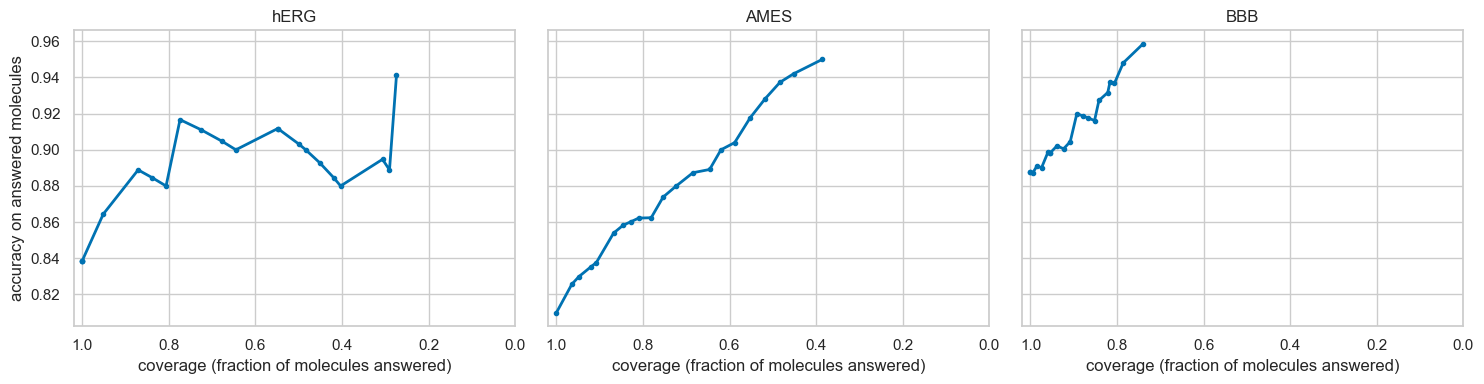

,coverage with guardrails,accuracy (all),accuracy (in-domain filter only),accuracy (uncertainty band only),accuracy (answered only),abstained as OUT OF DOMAIN,abstained as UNCERTAIN
endpoint,,,,,,,
hERG,51.6%,83.9%,92.1%,88.5%,93.8%,38.7%,9.7%
AMES,76.0%,81.0%,80.7%,85.4%,85.0%,12.1%,11.8%
BBB,79.1%,88.8%,90.1%,89.9%,91.6%,17.3%,3.6%


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
cov_rows = []
for ax, ep in zip(axes, data):
    tr, va, te = data[ep].store["split"]; y = data[ep].store["y"][te]; sim, p = ad_cache[ep]
    conf = np.abs(p - 0.5)
    thresholds = np.linspace(0, 0.4, 21)
    cov = [(conf >= t).mean() for t in thresholds]
    acc = [(((p >= 0.5) == y)[conf >= t]).mean() if (conf >= t).sum() > 0 else np.nan for t in thresholds]
    ax.plot(cov, acc, color="#0072B2", lw=2, marker="o", ms=3)
    ax.set_xlabel("coverage (fraction of molecules answered)"); ax.set_title(ep); ax.set_xlim(1.02, 0)
    ans = core.UNCERTAIN_BAND
    mask = (sim >= core.AD_SIM_MIN) & ~((p > ans[0]) & (p < ans[1]))
    in_dom = sim >= core.AD_SIM_MIN; confident = ~((p > ans[0]) & (p < ans[1]))
    cov_rows.append({"endpoint": ep, "coverage with guardrails": mask.mean(),
                     "accuracy (all)": ((p >= 0.5) == y).mean(),
                     "accuracy (in-domain filter only)": ((p >= 0.5) == y)[in_dom].mean(),
                     "accuracy (uncertainty band only)": ((p >= 0.5) == y)[confident].mean(),
                     "accuracy (answered only)": ((p >= 0.5) == y)[mask].mean(),
                     "abstained as OUT OF DOMAIN": (sim < core.AD_SIM_MIN).mean(),
                     "abstained as UNCERTAIN": ((p > ans[0]) & (p < ans[1]) & (sim >= core.AD_SIM_MIN)).mean()})
axes[0].set_ylabel("accuracy on answered molecules"); plt.tight_layout(); plt.show()
display(pd.DataFrame(cov_rows).set_index("endpoint").style.format("{:.1%}"))

**Reading the curves.** For AMES and BBB, accuracy rises smoothly as we answer fewer, more confident molecules (AMES from 81% to about 95% at ~40% coverage; BBB from 89% to about 96% at ~75% coverage). The hERG curve is bumpy because its test set is only 62 molecules.

**With the full guardrails switched on** (similarity ≥ 0.30 *and* probability outside 0.40–0.60, both fixed in advance and never tuned on the test set):

| Endpoint | Coverage | Accuracy (answered only) | Accuracy (everything) | Abstained: out of domain / uncertain |
|---|---|---|---|---|
| hERG | 51.6% | **93.8%** | 83.9% | 38.7% / 9.7% |
| AMES | 76.0% | **85.0%** | 81.0% | 12.1% / 11.8% |
| BBB | 79.1% | **91.6%** | 88.8% | 17.3% / 3.6% |

Note how often the hERG model abstains: 39% of its test molecules are out of domain. The scaffold split is deliberately hard, and the honest message for a medicinal chemist is that on genuinely novel chemotypes **the hERG model will often say "I don't know"**. In a safety setting that is the behaviour we want.

**Which guardrail does the work?** Separating the two shows they are not equally useful:

| Endpoint | Accuracy, everything | In-domain filter only | Uncertainty band only | Both |
|---|---|---|---|---|
| hERG | 83.9% | **92.1%** | 88.5% | 93.8% |
| AMES | 81.0% | 80.7% | **85.4%** | 85.0% |
| BBB | 88.8% | 90.1% | 89.9% | 91.6% |

For **hERG** the applicability-domain filter does most of the work. For **AMES** it does essentially nothing (80.7% against 81.0%); the whole gain comes from the uncertainty band, which by construction removes the molecules the model is least sure about. So the evidence for the applicability-domain flag rests mainly on hERG (24 out-of-domain test molecules), and we should not claim more than that.

### 8.2 What does "LOW RISK" really mean? Sensitivity, NPV and a safety-tuned threshold

For a toxicity screen, **missing a toxic compound is the costly mistake**, and plain accuracy hides it. So we report, on the test set, the **sensitivity** (fraction of true positives caught), the **specificity**, and the **negative predictive value (NPV)**: *of the molecules we call safe, how many really are?* We give NPV for the unguarded 0.5 cut-off and for the molecules that receive a "negative" verdict once all guardrails are on (LOW RISK for hERG/AMES; BBB- for BBB), with a 95% Wilson interval. Finally we show a **safety-tuned threshold**: the highest cut-off on the *validation* set that still catches &ge;90% of positives, applied unchanged to the test set.

In [28]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p_, d = k / n, 1 + z * z / n; c = p_ + z * z / (2 * n); a = z * np.sqrt(p_ * (1 - p_) / n + z * z / (4 * n * n))
    return ((c - a) / d, (c + a) / d)

safety_rows = []
for ep, df in data.items():
    tr, va, te = df.store["split"]; y = df.store["y"]; yt = y[te]; sim, p = ad_cache[ep]
    pv = calibrators[ep].predict(preds[ep][DEPLOY[ep]][0][0]); info = core.ENDPOINT_INFO[ep]
    verdicts = np.array([core.verdict(ep, pi, si) for pi, si in zip(p, sim)]); neg_call = verdicts == info["neg"]
    k, n = int((yt[neg_call] == 0).sum()), int(neg_call.sum()); lo, hi = wilson(k, n)
    grid = np.linspace(0.05, 0.95, 91)
    ok = [t for t in grid if (pv[y[va] == 1] >= t).mean() >= 0.90]; t90 = max(ok) if ok else 0.05
    safety_rows.append({"endpoint": ep,
        "sensitivity @0.5": (p[yt == 1] >= 0.5).mean(), "specificity @0.5": (p[yt == 0] < 0.5).mean(),
        "NPV @0.5": (yt[p < 0.5] == 0).mean(),
        "n 'negative' verdicts (guardrails on)": n, "NPV of those": k / n if n else np.nan,
        "NPV 95% CI": f"[{lo:.2f}, {hi:.2f}]", "positives wrongly among them": n - k,
        "safety threshold (90% sens. on valid)": t90,
        "sensitivity @safety thr": (p[yt == 1] >= t90).mean(), "specificity @safety thr": (p[yt == 0] < t90).mean()})
safety = pd.DataFrame(safety_rows).set_index("endpoint"); display(safety.round(3).T)

endpoint,hERG,AMES,BBB
sensitivity @0.5,0.86,0.811,0.98
specificity @0.5,0.789,0.809,0.578
NPV @0.5,0.714,0.78,0.897
n 'negative' verdicts (guardrails on),5,223,21
NPV of those,0.8,0.803,0.905
NPV 95% CI,"[0.38, 0.96]","[0.75, 0.85]","[0.71, 0.97]"
positives wrongly among them,1,44,2
safety threshold (90% sens. on valid),0.51,0.33,0.61
sensitivity @safety thr,0.86,0.882,0.954
specificity @safety thr,0.789,0.66,0.622


**What this says.**
- **"LOW RISK" is not clearance, and the numbers show it.** For AMES, 223 test molecules receive a LOW RISK verdict and **44 of them (about 20%) are in fact mutagenic** (NPV 0.80, 95% CI 0.75 to 0.85). At the plain 0.5 cut-off the model catches 81% of mutagens and 86% of hERG blockers, so roughly one true toxicant in five (AMES) or one in seven (hERG) slips through.
- **hERG is too small to say much.** Only 5 test molecules end up with a LOW RISK verdict (the guardrails abstain often and the set is about 70% positive), so its NPV of 0.80 has a 95% interval of 0.38 to 0.96.
- **A safety-tuned threshold trades specificity for sensitivity.** Lowering the AMES cut-off to 0.33 (chosen on validation to reach 90% sensitivity) lifts test sensitivity from 0.81 to 0.88 but drops specificity from 0.81 to 0.66, so many more good compounds are flagged. It did not quite reach 90% on the test set (the validation-to-test gap again). For hERG the validation-chosen cut-off is essentially the default (0.51) and changes nothing.
- **BBB** is shown for completeness. Its "positive" class (crosses the barrier) is a property, not a hazard, so the safety framing applies to hERG and AMES.

Practical message for the app: report the verdict *and* this caveat, and let the user pick a more cautious cut-off when missing a toxic compound is costly.

## 9 &middot; Guardrail 3: input validation, edge cases and bias &nbsp;&#9201;&#65039; ~6 min

### 9.1 Edge-case stress test

A deployed tool will be fed garbage: empty strings, typos, salts, metals, peptides, polymers. Every one of these should produce a *clear, safe* response &mdash; never a crash and never a confident number on something the model was not built for. We state the expected behaviour first, then test it automatically.

In [29]:
edge_cases = [
    ("empty string", "", "rejected"),
    ("None", None, "rejected"),
    ("gibberish", "this is not a molecule", "rejected"),
    ("unbalanced ring", "c1ccccc", "rejected"),
    ("water", "O", "rejected"),
    ("methane (too small)", "C", "rejected"),
    ("table salt (inorganic)", "[Na+].[Cl-]", "rejected"),
    ("cisplatin (metal)", "N[Pt](N)(Cl)Cl", "rejected"),
    ("giant polymer chain", "C" * 200, "rejected"),
    ("aspirin sodium salt", "CC(=O)Oc1ccccc1C(=O)[O-].[Na+]", "ok"),
    ("aspirin, messy whitespace", "  CC(=O)Oc1ccccc1C(=O)O \n", "ok"),
    ("aspirin, non-canonical SMILES", "OC(=O)c1ccccc1OC(C)=O", "ok"),
    ("quaternary ammonium", "C[N+](C)(C)CCOC(C)=O", "ok"),
    ("drug-like normal case", "CC(C)Cc1ccc(cc1)C(C)C(=O)O", "ok"),
]
rows = []
for name, smi, expected in edge_cases:
    mol, status, notes = core.check_smiles(smi)
    rows.append({"case": name, "expected": expected, "got": status, "pass": "PASS" if status == expected else "FAIL",
                 "message": " ".join(notes)})
edge = pd.DataFrame(rows); display(edge)
assert (edge["pass"] == "PASS").all(), "an edge case behaved unexpectedly"
# identical molecule written three different ways must yield identical predictions (canonicalisation check)
variants = ["CC(=O)Oc1ccccc1C(=O)O", "OC(=O)c1ccccc1OC(C)=O", "CC(=O)Oc1ccccc1C(=O)[O-].[Na+]"]
canon = {Chem.MolToSmiles(core.check_smiles(v)[0]) for v in variants}
print("Three spellings of aspirin collapse to", len(canon), "canonical structure:", canon)

,case,expected,got,pass,message
0,empty string,rejected,rejected,PASS,Empty input.
1,None,rejected,rejected,PASS,Empty input.
2,gibberish,rejected,rejected,PASS,Could not parse SMILES.
3,unbalanced ring,rejected,rejected,PASS,Could not parse SMILES.
4,water,rejected,rejected,PASS,Inorganic / no carbon: outside the scope of th...
5,methane (too small),rejected,rejected,PASS,Too small (1 heavy atoms; minimum 3).
6,table salt (inorganic),rejected,rejected,PASS,Inorganic / no carbon: outside the scope of th...
7,cisplatin (metal),rejected,rejected,PASS,Inorganic / no carbon: outside the scope of th...
8,giant polymer chain,rejected,rejected,PASS,Too large (200 heavy atoms; maximum 150).
9,aspirin sodium salt,ok,ok,PASS,Multi-component input (salt/mixture): largest ...


Three spellings of aspirin collapse to 1 canonical structure: {'CC(=O)Oc1ccccc1C(=O)O'}


### 9.2 Bias / subgroup testing

"Bias" in a chemistry model means **systematically worse performance on some kinds of molecules**. We can't audit demographic bias here (the data are molecules, not patients), but we can audit **chemical-space bias**: does performance degrade for large molecules, greasy molecules, or novel scaffolds? If so, users must be told. We split the **test set** into tertiles by molecular weight and logP and report AUC in each. (Very small groups make AUC noisy; read the `n` column.)

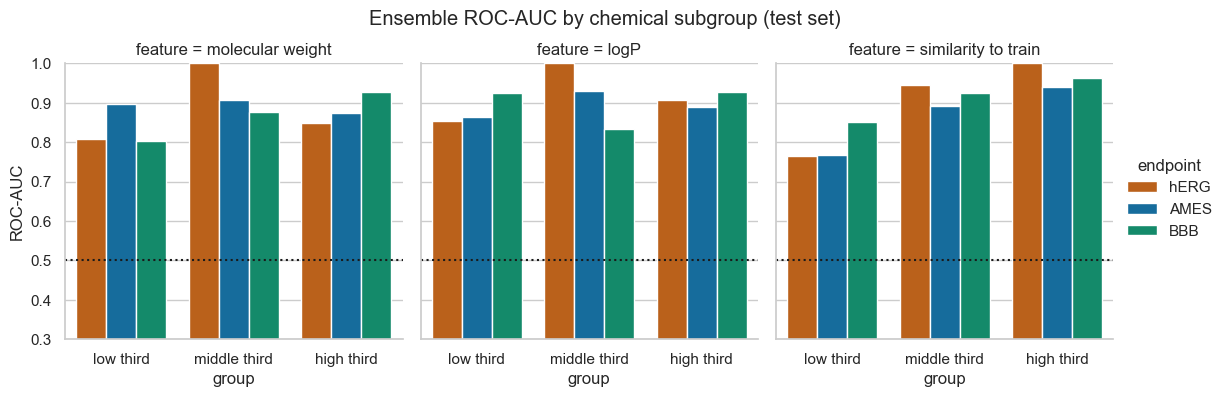

endpoint                          AMES   BBB  hERG
feature             group                         
logP                high third    0.89  0.93  0.91
                    low third     0.86  0.92  0.85
                    middle third  0.93  0.83  1.00
molecular weight    high third    0.87  0.93  0.85
                    low third     0.90  0.80  0.81
                    middle third  0.91  0.88  1.00
similarity to train high third    0.94  0.96  1.00
                    low third     0.77  0.85  0.77
                    middle third  0.89  0.92  0.95

In [30]:
sub_rows = []
for ep, df in data.items():
    tr, va, te = df.store["split"]; y = df.store["y"][te]
    p = np.mean([preds[ep]["Ensemble"][s][1] for s in SEEDS], axis=0)
    mw = df.mol.iloc[te].apply(Descriptors.MolWt).to_numpy(); lp = df.mol.iloc[te].apply(Descriptors.MolLogP).to_numpy()
    sim = ad_cache[ep][0]
    for fname, vals in [("molecular weight", mw), ("logP", lp), ("similarity to train", sim)]:
        q = pd.qcut(vals, 3, labels=["low third", "middle third", "high third"], duplicates="drop")
        for lab in q.categories:
            m = np.asarray(q == lab)
            if m.sum() >= 8 and len(set(y[m])) == 2:
                sub_rows.append({"endpoint": ep, "feature": fname, "group": lab, "n": int(m.sum()), "ROC-AUC": roc_auc_score(y[m], p[m])})
sub = pd.DataFrame(sub_rows)
g = sns.catplot(data=sub, x="group", y="ROC-AUC", hue="endpoint", col="feature", kind="bar",
                palette=["#D55E00", "#0072B2", "#009E73"], height=3.8, aspect=1.0)
for ax in g.axes.flat: ax.axhline(0.5, color="k", ls=":"); ax.set_ylim(0.3, 1)
g.fig.suptitle("Ensemble ROC-AUC by chemical subgroup (test set)", y=1.04); plt.show()
display(sub.pivot_table(index=["feature", "group"], columns="endpoint", values="ROC-AUC").round(2))

**What we see (with caution: each bar covers only ~20 to ~240 molecules, and these subgroup scores use the ensemble, so they shift slightly between reruns).**

- **Similarity to the training set** is the one consistent pattern. The lowest third has ROC-AUC 0.77 (AMES), 0.85 (BBB) and 0.77 (hERG), against 0.94, 0.96 and 1.00 for the highest third. The model is clearly less reliable on chemistry unlike its training data.
- **Molecular weight and logP** show no systematic pattern. One dip is worth noting: for BBB the low-molecular-weight third scores 0.80 against 0.88–0.93 elsewhere, so very small molecules are the least well served. The hERG middle third reading 1.00 on about twenty molecules is small-sample luck, not skill.
- **Not tested:** anything demographic (the data are molecules, not patients); peptides, macrocycles and natural products (rare in the training data); permanently charged species. These belong on the limitations list.

## 10 &middot; Stress-test error analysis log &nbsp;&#9201;&#65039; ~5 min

Averages hide failures; individual mistakes teach. For each endpoint we list the most **confidently wrong** test predictions (highest-probability false positives, lowest-probability false negatives) with their key properties. In a toxicity setting the two error types have *different* costs:

- **False negative** (we say "safe", it is toxic): a dangerous compound advances. *Costly and potentially harmful.*
- **False positive** (we say "toxic", it is fine): a good compound is dropped. *A lost opportunity, usually cheaper.*

In [31]:
log_rows = []
for ep, df in data.items():
    tr, va, te = df.store["split"]; y = df.store["y"]
    sim, p = ad_cache[ep]
    t = df.iloc[te].copy(); t["p"] = p; t["sim"] = sim
    t["MW"] = t.mol.apply(Descriptors.MolWt); t["logP"] = t.mol.apply(Descriptors.MolLogP)
    fn = t[(t.Y == 1)].nsmallest(3, "p"); fp = t[(t.Y == 0)].nlargest(3, "p")
    for kind, sub_t in [("FALSE NEGATIVE (missed positive)", fn), ("FALSE POSITIVE (false alarm)", fp)]:
        for _, r in sub_t.iterrows():
            log_rows.append({"endpoint": ep, "error type": kind, "p(positive)": round(r.p, 2), "true": int(r.Y),
                             "sim to train": round(r.sim, 2), "MW": round(r.MW), "logP": round(r.logP, 1), "SMILES": r.smiles})
error_log = pd.DataFrame(log_rows)
pd.set_option("display.max_colwidth", 70); display(error_log)
error_log.to_csv("error_analysis_log.csv", index=False)

,endpoint,error type,p(positive),true,sim to train,MW,logP,SMILES
0,hERG,FALSE NEGATIVE (missed positive),0.08,1,0.35,247,2.2,CCOC(=O)C1(c2ccccc2)CCN(C)CC1
1,hERG,FALSE NEGATIVE (missed positive),0.10,1,0.21,266,2.4,O=C1CCC(c2ccc(Nc3ccncc3)cc2)=NN1
2,hERG,FALSE NEGATIVE (missed positive),0.28,1,0.20,259,2.8,COc1cc(N[C@H](C)CCCN)c2ncccc2c1
3,hERG,FALSE POSITIVE (false alarm),0.85,0,0.25,514,6.0,Cc1nnc(C(C)C)n1C1C[C@H]2CC[C@@H](C1)N2CC[C@H](NC(=O)C1CCC(F)(F)CC1...
4,hERG,FALSE POSITIVE (false alarm),0.64,0,0.31,340,2.9,N=C(N)c1ccc(OCCCCCOc2ccc(C(=N)N)cc2)cc1
5,hERG,FALSE POSITIVE (false alarm),0.57,0,0.21,407,2.0,N[C@@H](CC(=O)N1CCn2c(nnc2C(F)(F)F)C1)Cc1cc(F)c(F)cc1F
6,AMES,FALSE NEGATIVE (missed positive),0.02,1,0.57,291,3.5,CC(C)(C)NCC(O)COc1ccccc1C1CCCC1
7,AMES,FALSE NEGATIVE (missed positive),0.05,1,0.57,372,4.9,[O-][S+](c1cc(Cl)cc(Cl)c1O)c1cc(Cl)cc(Cl)c1O
8,AMES,FALSE NEGATIVE (missed positive),0.06,1,0.35,222,3.0,CC(C)=CCC[C@@](C)(O)[C@H]1CCC=CC1=O
9,AMES,FALSE POSITIVE (false alarm),0.98,0,0.54,284,5.0,Cc1ccc2cc3c(ccc4ccccc43)c3c2c1C(O)C3


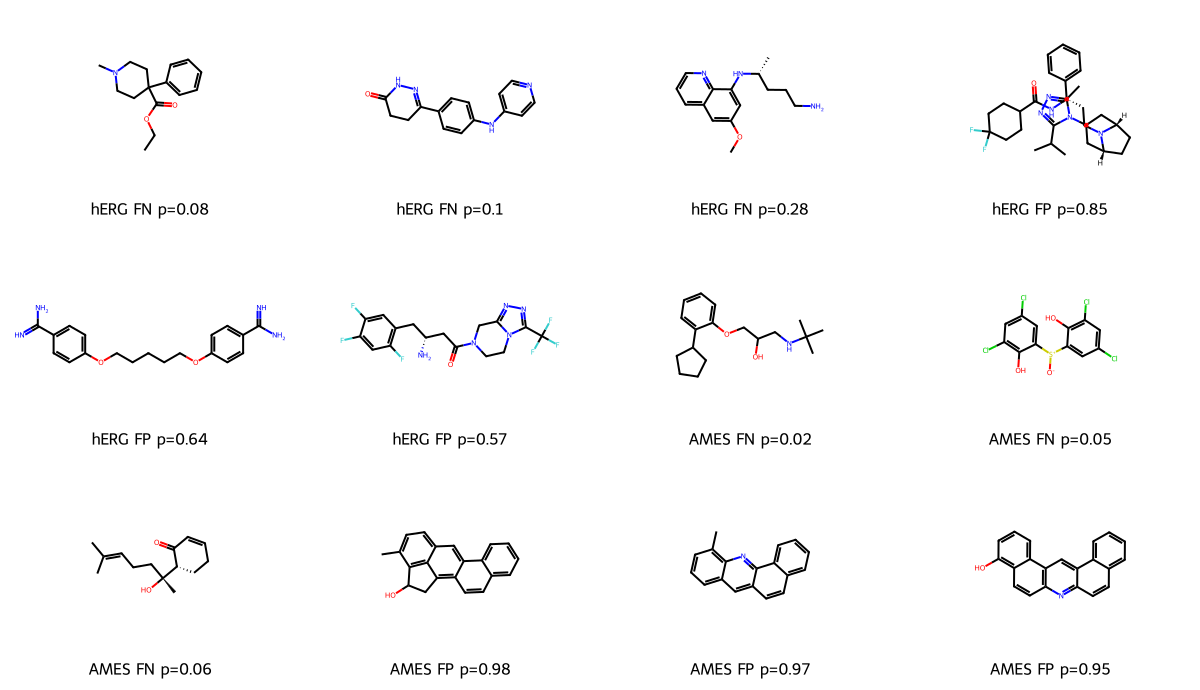

In [32]:
worst = error_log[error_log.endpoint.isin(["hERG", "AMES"])]
mols = [Chem.MolFromSmiles(s) for s in worst.SMILES]
legends = [f"{r.endpoint} {'FN' if 'NEG' in r['error type'] else 'FP'} p={r['p(positive)']}" for _, r in worst.iterrows()]
Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(300, 230), legends=legends)

**What the mistakes teach us** (compound names are our own identification from the structures; treat them as informative, not authoritative).

*hERG.* The three **missed blockers** are small, relatively polar molecules that look like pethidine (meperidine) and primaquine, nothing like the large, greasy blockers the model has learned. Two of the three have similarity < 0.30 to the training set, so the **applicability-domain guardrail would have flagged them** instead of calling them safe. The **false alarms** include maraviroc, a drug that chemists *deliberately engineered to avoid hERG*; the model sees "large, lipophilic, basic amine" and cannot see the subtle design that rescued it. Also in the list is pentamidine, labelled a non-blocker here even though it is clinically reported to prolong QT (through a different mechanism), so even the label is debatable.

*AMES.* The false alarms are **polycyclic aromatic and aza-arene compounds** (for example a hydroxylated 3-methylcholanthrene), a chemotype that is usually mutagenic but labelled negative here. Importantly, they are **in domain** (similarity 0.54–0.73): the model is confidently wrong *inside* its comfort zone, which the applicability-domain check cannot catch. The missed positives include an α,β-unsaturated ketone (a textbook structural alert the model failed to use) and a beta-blocker (penbutolol) whose positive label is surprising.

*BBB.* Many apparent errors look like **label ambiguity or biology the descriptors can't see**: an aminoglycoside antibiotic (amikacin-like, MW 586, logP −8) is labelled BBB-positive; folinic acid is plausibly transporter-mediated; and small lipophilic amines such as pheniramine, nicotinyl alcohol and dicyclomine are labelled non-penetrant although they look CNS-like.

**Lessons.**
1. The *costly* error type for hERG and AMES is the false negative (a dangerous compound advances). A "LOW RISK" verdict must therefore be read as "no alarm raised", never as clearance.
2. The applicability-domain guard catches some but not all failures (it would have caught two of the three hERG misses but none of the AMES ones).
3. Part of the "error" is label noise in public data, which caps what any model can score.

## 11 &middot; From model to product &nbsp;&#9201;&#65039; ~8 min

### 11.1 Package the deployable model

We deploy the calibrated, validation-selected tree ensemble (section 6.1) for each endpoint. The bundle stores, per endpoint: the model, its Platt calibrator (fitted on validation), and the **training fingerprints** needed for the applicability-domain check. (For a real production release you would refit on train+validation+test; we keep the held-out test set untouched so every number above stays honest.)

In [33]:
bundle = {"endpoints": {}, "meta": {"split": "scaffold 80/10/10", "features": "ECFP4 counts + MACCS + RDKit 2D", "seeds": SEEDS}}
for ep, df in data.items():
    tr, va, te = df.store["split"]
    bundle["endpoints"][ep] = {"model": fitted[ep][FITTED_KEY[DEPLOY[ep]]], "calibrator": calibrators[ep],
                               "train_fps": [df.store["fps"][i] for i in tr],
                               "train_smiles": set(df.smiles.iloc[tr])}
joblib.dump(bundle, "admet_bundle.joblib")
print(f"Saved admet_bundle.joblib ({os.path.getsize('admet_bundle.joblib')/1e6:.1f} MB)")

Saved admet_bundle.joblib (86.5 MB)


### 11.2 Screen a candidate library of well-known drugs

A final sanity check that doubles as a demo: score a small "candidate library" of drugs whose behaviour is well documented in the literature, and compare with what we expect. Two honesty features: an **`in training set`** flag (if the model has *seen* the molecule, agreement is memory, not prediction) and the **verdict** produced by the real guardrail logic.

*Literature expectations (from drug labels and the medicinal-chemistry literature):* terfenadine, astemizole, cisapride, dofetilide and haloperidol block hERG; fexofenadine (the safer terfenadine metabolite) does not block meaningfully; benzo[a]pyrene, 2-aminofluorene and nitrofurantoin are Ames-positive; ibuprofen and paracetamol are Ames-negative; caffeine, diazepam and haloperidol enter the brain, while atenolol and fexofenadine are largely peripherally restricted.

In [34]:
library = {
 "terfenadine": "CC(C)(C)c1ccc(cc1)C(O)CCCN1CCC(CC1)C(O)(c1ccccc1)c1ccccc1",
 "astemizole": "COc1ccc(CCN2CCC(CC2)Nc2nc3ccccc3n2Cc2ccc(F)cc2)cc1",
 "cisapride": "COC1CN(CCCOc2ccc(F)cc2)CCC1NC(=O)c1cc(N)c(Cl)cc1OC",
 "dofetilide": "CN(CCOc1ccc(NS(C)(=O)=O)cc1)CCc1ccc(NS(C)(=O)=O)cc1",
 "haloperidol": "OC1(CCN(CCCC(=O)c2ccc(F)cc2)CC1)c1ccc(Cl)cc1",
 "fexofenadine": "CC(C)(C(=O)O)c1ccc(cc1)C(O)CCCN1CCC(CC1)C(O)(c1ccccc1)c1ccccc1",
 "benzo[a]pyrene": "c1ccc2c(c1)cc1ccc3cccc4ccc2c1c34",
 "2-aminofluorene": "Nc1ccc2c(c1)Cc1ccccc12",
 "nitrofurantoin": "O=C1CN(N=Cc2ccc([N+](=O)[O-])o2)C(=O)N1",
 "ibuprofen": "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
 "paracetamol": "CC(=O)Nc1ccc(O)cc1",
 "caffeine": "Cn1cnc2c1c(=O)n(C)c(=O)n2C",
 "diazepam": "CN1C(=O)CN=C(c2ccccc2)c2cc(Cl)ccc12",
 "atenolol": "CC(C)NCC(O)COc1ccc(CC(N)=O)cc1",
 "aspirin": "CC(=O)Oc1ccccc1C(=O)O",
 "metformin": "CN(C)C(=N)N=C(N)N",
}
screen = core.predict_smiles(list(library.values()), bundle)
screen.insert(0, "drug", list(library))
for ep in bundle["endpoints"]:
    seen = bundle["endpoints"][ep]["train_smiles"]
    screen[f"{ep}_seen"] = screen.canonical.apply(lambda s: s in seen)
view = screen[["drug"] + [f"{ep}_{k}" for ep in bundle["endpoints"] for k in ("prob", "verdict")]].copy()
for ep in bundle["endpoints"]: view[f"{ep}_prob"] = view[f"{ep}_prob"].round(2)
display(view.set_index("drug"))
print("Molecules the model has SEEN in training (agreement there is memory, not prediction):")
print({ep: list(screen.loc[screen[f'{ep}_seen'], 'drug']) for ep in bundle['endpoints']})

,hERG_prob,hERG_verdict,AMES_prob,AMES_verdict,BBB_prob,BBB_verdict
drug,,,,,,
terfenadine,0.96,HIGH RISK,0.09,LOW RISK,0.21,BBB- (peripherally restricted)
astemizole,1.00,HIGH RISK,0.20,LOW RISK,0.91,OUT OF DOMAIN
cisapride,0.99,HIGH RISK,0.17,OUT OF DOMAIN,0.95,BBB+ (CNS exposure)
dofetilide,0.82,HIGH RISK,0.27,LOW RISK,0.67,BBB+ (CNS exposure)
haloperidol,0.99,HIGH RISK,0.02,LOW RISK,1.00,BBB+ (CNS exposure)
fexofenadine,0.51,UNCERTAIN,0.09,LOW RISK,0.11,BBB- (peripherally restricted)
benzo[a]pyrene,0.21,OUT OF DOMAIN,1.00,HIGH RISK,0.85,OUT OF DOMAIN
2-aminofluorene,0.02,OUT OF DOMAIN,1.00,HIGH RISK,0.95,BBB+ (CNS exposure)
nitrofurantoin,0.00,LOW RISK,1.00,HIGH RISK,0.67,OUT OF DOMAIN


Molecules the model has SEEN in training (agreement there is memory, not prediction):
{'hERG': ['astemizole', 'haloperidol', 'caffeine'], 'AMES': ['haloperidol', 'benzo[a]pyrene', '2-aminofluorene', 'ibuprofen', 'paracetamol', 'caffeine', 'diazepam', 'atenolol', 'aspirin'], 'BBB': ['terfenadine', 'haloperidol', 'fexofenadine', 'ibuprofen', 'paracetamol', 'caffeine', 'diazepam', 'atenolol']}


**Reading the screen honestly.**

- **Genuinely unseen drugs (the real test).** For hERG, terfenadine, cisapride and dofetilide were *not* in the training data, and the model correctly flags all three as HIGH RISK (0.96, 0.99, 0.82). **Fexofenadine**, whose added carboxylic acid is precisely what removed terfenadine's hERG liability, comes out **UNCERTAIN (0.51)**: plausibly because the model sees the shared skeleton but also the acid (we have not verified this), and the uncertainty band turns a likely wrong answer into a shrug. For AMES, **nitrofurantoin** (unseen) is correctly HIGH RISK (1.00).
- **Seen drugs prove little.** Benzo[a]pyrene and 2-aminofluorene (AMES), and caffeine, diazepam, haloperidol, atenolol and fexofenadine (BBB) all agree with the literature, but every one of them is in the corresponding training set, so that agreement is recall, not prediction.
- **The guardrails behave as designed.** For hERG, ibuprofen, benzo[a]pyrene, 2-aminofluorene and metformin are flagged OUT OF DOMAIN; aspirin's BBB probability of 0.51 and caffeine's hERG probability of 0.46 both become UNCERTAIN.
- This is a 16-drug sanity check: small, hand-picked and partly seen. The real evidence is the scaffold-split benchmark in section 5.

### 11.3 The Gradio app (minimum viable product)

The app lives in `app.py` in the repo (the cell below smoke-tests it): paste one or more SMILES (one per line) and get a traffic-light table plus structure images. It imports the very same `admet_core.py` and `admet_bundle.joblib` that we just tested. To use it:

- **Locally:** `pip install -r requirements.txt` then `python app.py` (the model bundle downloads itself on first run)
- **Here in Colab:** set `LAUNCH_APP = True` in the next cell; Gradio prints a public link. (Or just open `Launch_App.ipynb` from the README's Colab badge.)

In [36]:
LAUNCH_APP = False        # set True in Colab to get a public link (blocks this cell while running)
if LAUNCH_APP:
    import subprocess, sys
    exec(open("app.py").read().replace('if __name__ == "__main__":', 'if True:').replace("demo.launch()", "demo.launch(share=True)"))
else:
    # smoke-test the app's logic without starting a server
    import importlib.util
    spec = importlib.util.spec_from_file_location("app_mod", "app.py"); app_mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(app_mod)
    tab, gal = app_mod.run("CC(=O)Oc1ccccc1C(=O)O\n[Na+].[Cl-]")
    display(tab); print(len(gal), "structure image(s) rendered")

,SMILES,status,hERG,hERG sim,AMES,AMES sim,BBB,BBB sim,in training set of,notes
0,CC(=O)Oc1ccccc1C(=O)O,ok,🟢 LOW RISK (p=0.01),0.31,🟢 LOW RISK (p=0.01),1.0,🟡 UNCERTAIN (p=0.51),0.45,AMES,
1,[Na+].[Cl-],rejected,-,NaN,-,NaN,-,NaN,-,Inorganic / no carbon: outside the scope of this model.


1 structure image(s) rendered


## 12 &middot; The story in one page &nbsp;&#9201;&#65039; ~3 min

**The problem.** Experimental ADMET screening is slow and expensive, and toxicity or distribution problems kill drug candidates late. A cheap computational triage that flags the worst liabilities *before* synthesis saves money and, more importantly, keeps unsafe chemistry away from patients.

**What we built.** A calibrated, explainable **three-endpoint triage panel** (hERG cardiotoxicity, Ames mutagenicity, blood–brain-barrier penetration) with a Gradio app. Every prediction is wrapped in guardrails: input validation, a calibrated probability, an "uncertain" band, and an applicability-domain check that answers **OUT OF DOMAIN** for molecules unlike the training data.

**How we kept it honest.** Duplicate and label-conflict removal; a scaffold split with an enforced zero-overlap assertion (and a class-balance search, after our first split turned out to be 100% positive in the BBB test set); baselines at every rung; three seeds; bootstrap confidence intervals; models and thresholds chosen on validation only; the test set never used for fitting, tuning or model selection.

**Headline results** (held-out scaffold test set, ROC-AUC, deployed Random Forest):

| Endpoint | Deployed Random Forest | Gain over logistic regression (95% CI) | Gain over nearest neighbour (95% CI) |
|---|---|---|---|
| hERG | **0.909** | +0.004 (−0.054 to +0.057): none detectable | +0.081 (−0.049 to +0.223) |
| AMES | **0.886** | +0.031 (+0.013 to +0.050) | +0.041 (+0.019 to +0.064) |
| BBB | **0.917** | +0.043 (−0.006 to +0.090) | +0.081 (+0.029 to +0.142) |

With the guardrails on, the panel answers 52% / 76% / 79% of test molecules (hERG / AMES / BBB) at 94% / 85% / 92% accuracy, versus 84% / 81% / 89% when forced to answer everything.

**What surprised us.** (1) A GNN trained from scratch lost to a Random Forest on every endpoint. (2) On hERG, plain logistic regression matched everything: with ~500 molecules, complexity does not pay. (3) Our first scaffold split silently produced test sets with the wrong class balance, a reminder to always print class balance per partition.

**Limitations to state out loud.** Small test sets (hERG n=62) mean wide intervals. The AMES model is confidently wrong on some polycyclic aromatics, inside its domain. Public labels contain noise. Probabilities for hERG are only approximately calibrated, and in the AMES test set about 20% of molecules given a LOW RISK verdict are actually mutagenic (44 of 223). The panel is a **research triage aid, not a clinical decision tool**: "LOW RISK" means "no alarm raised", never "safe".

**Next steps.** Pool more data (ChEMBL, PubChem); add explicit structural alerts for Ames; try pre-trained molecular representations; conformal prediction for guaranteed error rates; external validation on an in-house or newer dataset; refit on all data for release; extend to CYP inhibition, solubility and clearance.

In [38]:
# Save every headline artefact so the write-up never drifts from the code
bench.to_csv("benchmark_all_seeds.csv", index=False)
summ.to_csv("benchmark_summary.csv", index=False)
ci_table.to_csv("benchmark_ci.csv")
headline.to_csv("benchmark_deployed_vs_baselines.csv")
safety.to_csv("safety_metrics.csv")
edge.to_csv("edge_case_tests.csv", index=False)
screen.to_csv("library_screen.csv", index=False)
print("Saved:", [f for f in ['admet_core.py', 'app.py', 'requirements.txt', 'admet_bundle.joblib', 'benchmark_all_seeds.csv', 'benchmark_summary.csv', 'benchmark_ci.csv', 'benchmark_deployed_vs_baselines.csv', 'safety_metrics.csv', 'edge_case_tests.csv', 'error_analysis_log.csv', 'library_screen.csv'] if os.path.exists(f)])

Saved:

 ['admet_core.py', 'app.py', 'requirements.txt', 'admet_bundle.joblib', 'benchmark_all_seeds.csv', 'benchmark_summary.csv', 'benchmark_ci.csv', 'benchmark_deployed_vs_baselines.csv', 'safety_metrics.csv', 'edge_case_tests.csv', 'error_analysis_log.csv', 'library_screen.csv']
